In [ ]:
# Exclude other types of fraud, just keep only friendly fraud
import pandas as pd

# Read file
df = pd.read_csv('/content/sample_data/transactions.csv')

# Keep blank OR Friendly Fraud
filtered_df = df[
    (df['fraud_type'].isna()) |
    (df['fraud_type'] == 'friendly_fraud')
]

# Save to new file
filtered_df.to_excel('/content/friendly_fraud_only.xlsx', index=False)

In [ ]:
#4.1.1 Data overview
import pandas as pd
from scipy.stats import skew

# Read Excel file
df = pd.read_excel('/content/sample_data/friendly_fraud_only.xlsx')

# Select columns for numerical features
cols = [
    'amount',
    'ip_risk_score',
    'velocity_1h',
    'time_since_last_s',
    'amount_vs_avg_ratio',
    'account_age_days',
    'credit_limit',
    'hour_of_day'
]

# Create table
summary = pd.DataFrame({
    'Feature': cols,
    'Mean': [df[col].mean() for col in cols],
    'Std Dev': [df[col].std() for col in cols],
    'Min': [df[col].min() for col in cols],
    'Median': [df[col].median() for col in cols],
    'Max': [df[col].max() for col in cols],
    'Skewness': [skew(df[col].dropna()) for col in cols]
})

# Rounding
summary = summary.round(2)
display(summary)


,Feature,Mean,Std Dev,Min,Median,Max,Skewness
0,amount,174.52,265.78,1.83,80.08,8930.27,4.64
1,ip_risk_score,21.08,15.71,0.00,18.40,100.00,0.95
2,velocity_1h,1.00,1.01,0.00,1.00,12.00,1.06
3,time_since_last_s,180.09,180.14,1.00,125.00,2733.00,2.01
4,amount_vs_avg_ratio,3.13,6.04,0.01,1.27,353.76,7.66
5,account_age_days,1833.89,1046.30,30.00,1832.00,3649.00,0.01
6,credit_limit,6707.76,6173.89,500.00,4882.18,50000.00,2.76
7,hour_of_day,11.52,6.91,0.00,12.00,23.00,-0.00


In [ ]:
#4.1.1 Data overview
import pandas as pd

df = pd.read_excel('/content/sample_data/friendly_fraud_only.xlsx')
df['is_friendly_fraud'] = (df['fraud_pattern'] == 'friendly_fraud').astype(int)

# Select columns for categorical features
cat_cols = ['merchant_category', 'device_type', 'device_known',
            'is_foreign_txn', 'card_present', 'has_2fa', 'is_weekend']

# Mapping binary columns
df['device_known'] = df['device_known'].map({0: 'unknown', 1: 'known'})
df['is_foreign_txn'] = df['is_foreign_txn'].map({0: 'domestic', 1: 'foreign'})
df['card_present'] = df['card_present'].map({0: 'not present', 1: 'present'})
df['has_2fa'] = df['has_2fa'].map({0: 'disabled', 1: 'enabled'})
df['is_weekend'] = df['is_weekend'].map({0: 'weekday', 1: 'weekend'})


summary_cat = pd.DataFrame({
    'Feature': cat_cols,
    'Most Frequent': [f"{df[col].value_counts().index[0]} ({df[col].value_counts(normalize=True).iloc[0]*100:.1f}%)" for col in cat_cols],
    'Lowest Fraud Rate': [f"{df.groupby(col)['is_friendly_fraud'].mean().idxmin()} ({df.groupby(col)['is_friendly_fraud'].mean().min()*100:.3f}%)" for col in cat_cols],
    'Highest Fraud Rate': [f"{df.groupby(col)['is_friendly_fraud'].mean().idxmax()} ({df.groupby(col)['is_friendly_fraud'].mean().max()*100:.3f}%)" for col in cat_cols]
})

display(summary_cat)

,Feature,Most Frequent,Lowest Fraud Rate,Highest Fraud Rate
0,merchant_category,grocery (18.1%),atm (0.135%),crypto (0.495%)
1,device_type,mobile_app (39.9%),atm (0.120%),mobile_app (0.206%)
2,device_known,known (89.9%),known (0.088%),unknown (0.954%)
3,is_foreign_txn,domestic (71.0%),domestic (0.109%),foreign (0.338%)
4,card_present,not present (64.8%),present (0.126%),not present (0.202%)
5,has_2fa,enabled (64.9%),enabled (0.156%),disabled (0.212%)
6,is_weekend,weekday (71.3%),weekend (0.169%),weekday (0.178%)


/tmp/ipykernel_9950/2309750653.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[1].boxplot(


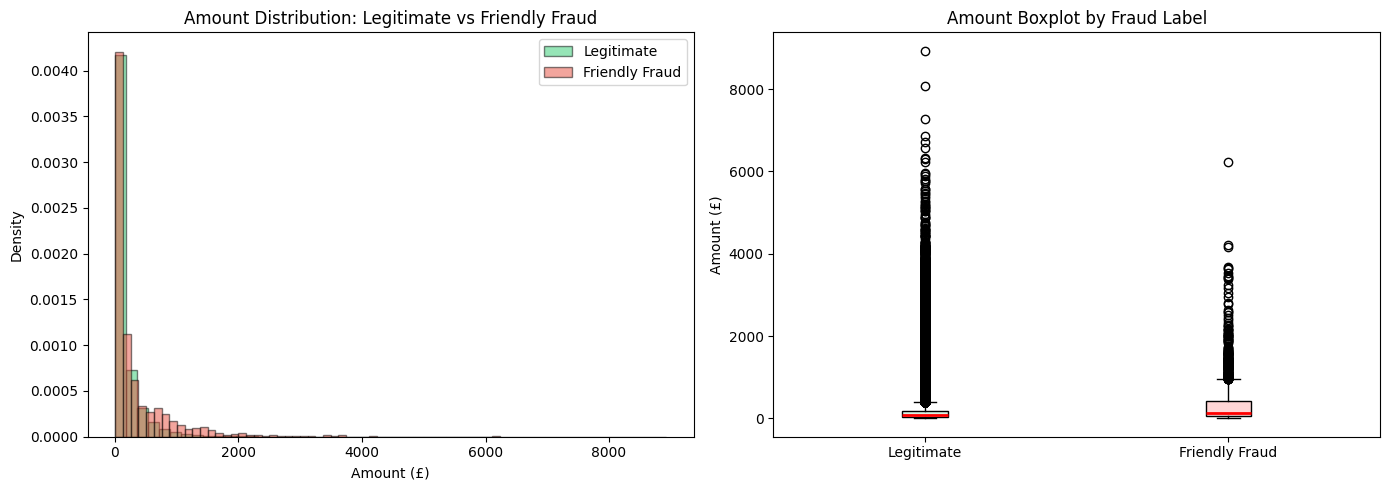

In [ ]:
#4.1.3 Transaction Amount Analysis
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# On the left: compare amount between 2 groups (using density)
for label, color, name in [(0, '#2ecc71', 'Legitimate'), (1, '#e74c3c', 'Friendly Fraud')]:
    subset = df[df['is_friendly_fraud'] == label]['amount']
    axes[0].hist(subset, bins=50, color=color, alpha=0.5,
                 label=name, edgecolor='black', density=True)
axes[0].set_title('Amount Distribution: Legitimate vs Friendly Fraud')
axes[0].set_xlabel('Amount (£)')
axes[0].set_ylabel('Density')
axes[0].legend()

# On the right: boxplot
bp = axes[1].boxplot(
    [df[df['is_friendly_fraud']==0]['amount'],
     df[df['is_friendly_fraud']==1]['amount']],
    labels=['Legitimate', 'Friendly Fraud'],
    patch_artist=True, medianprops=dict(color='red', linewidth=2))
bp['boxes'][0].set_facecolor('#d5f4e6')
bp['boxes'][1].set_facecolor('#ffd6d6')
axes[1].set_title('Amount Boxplot by Fraud Label')
axes[1].set_ylabel('Amount (£)')

plt.tight_layout()
plt.show()

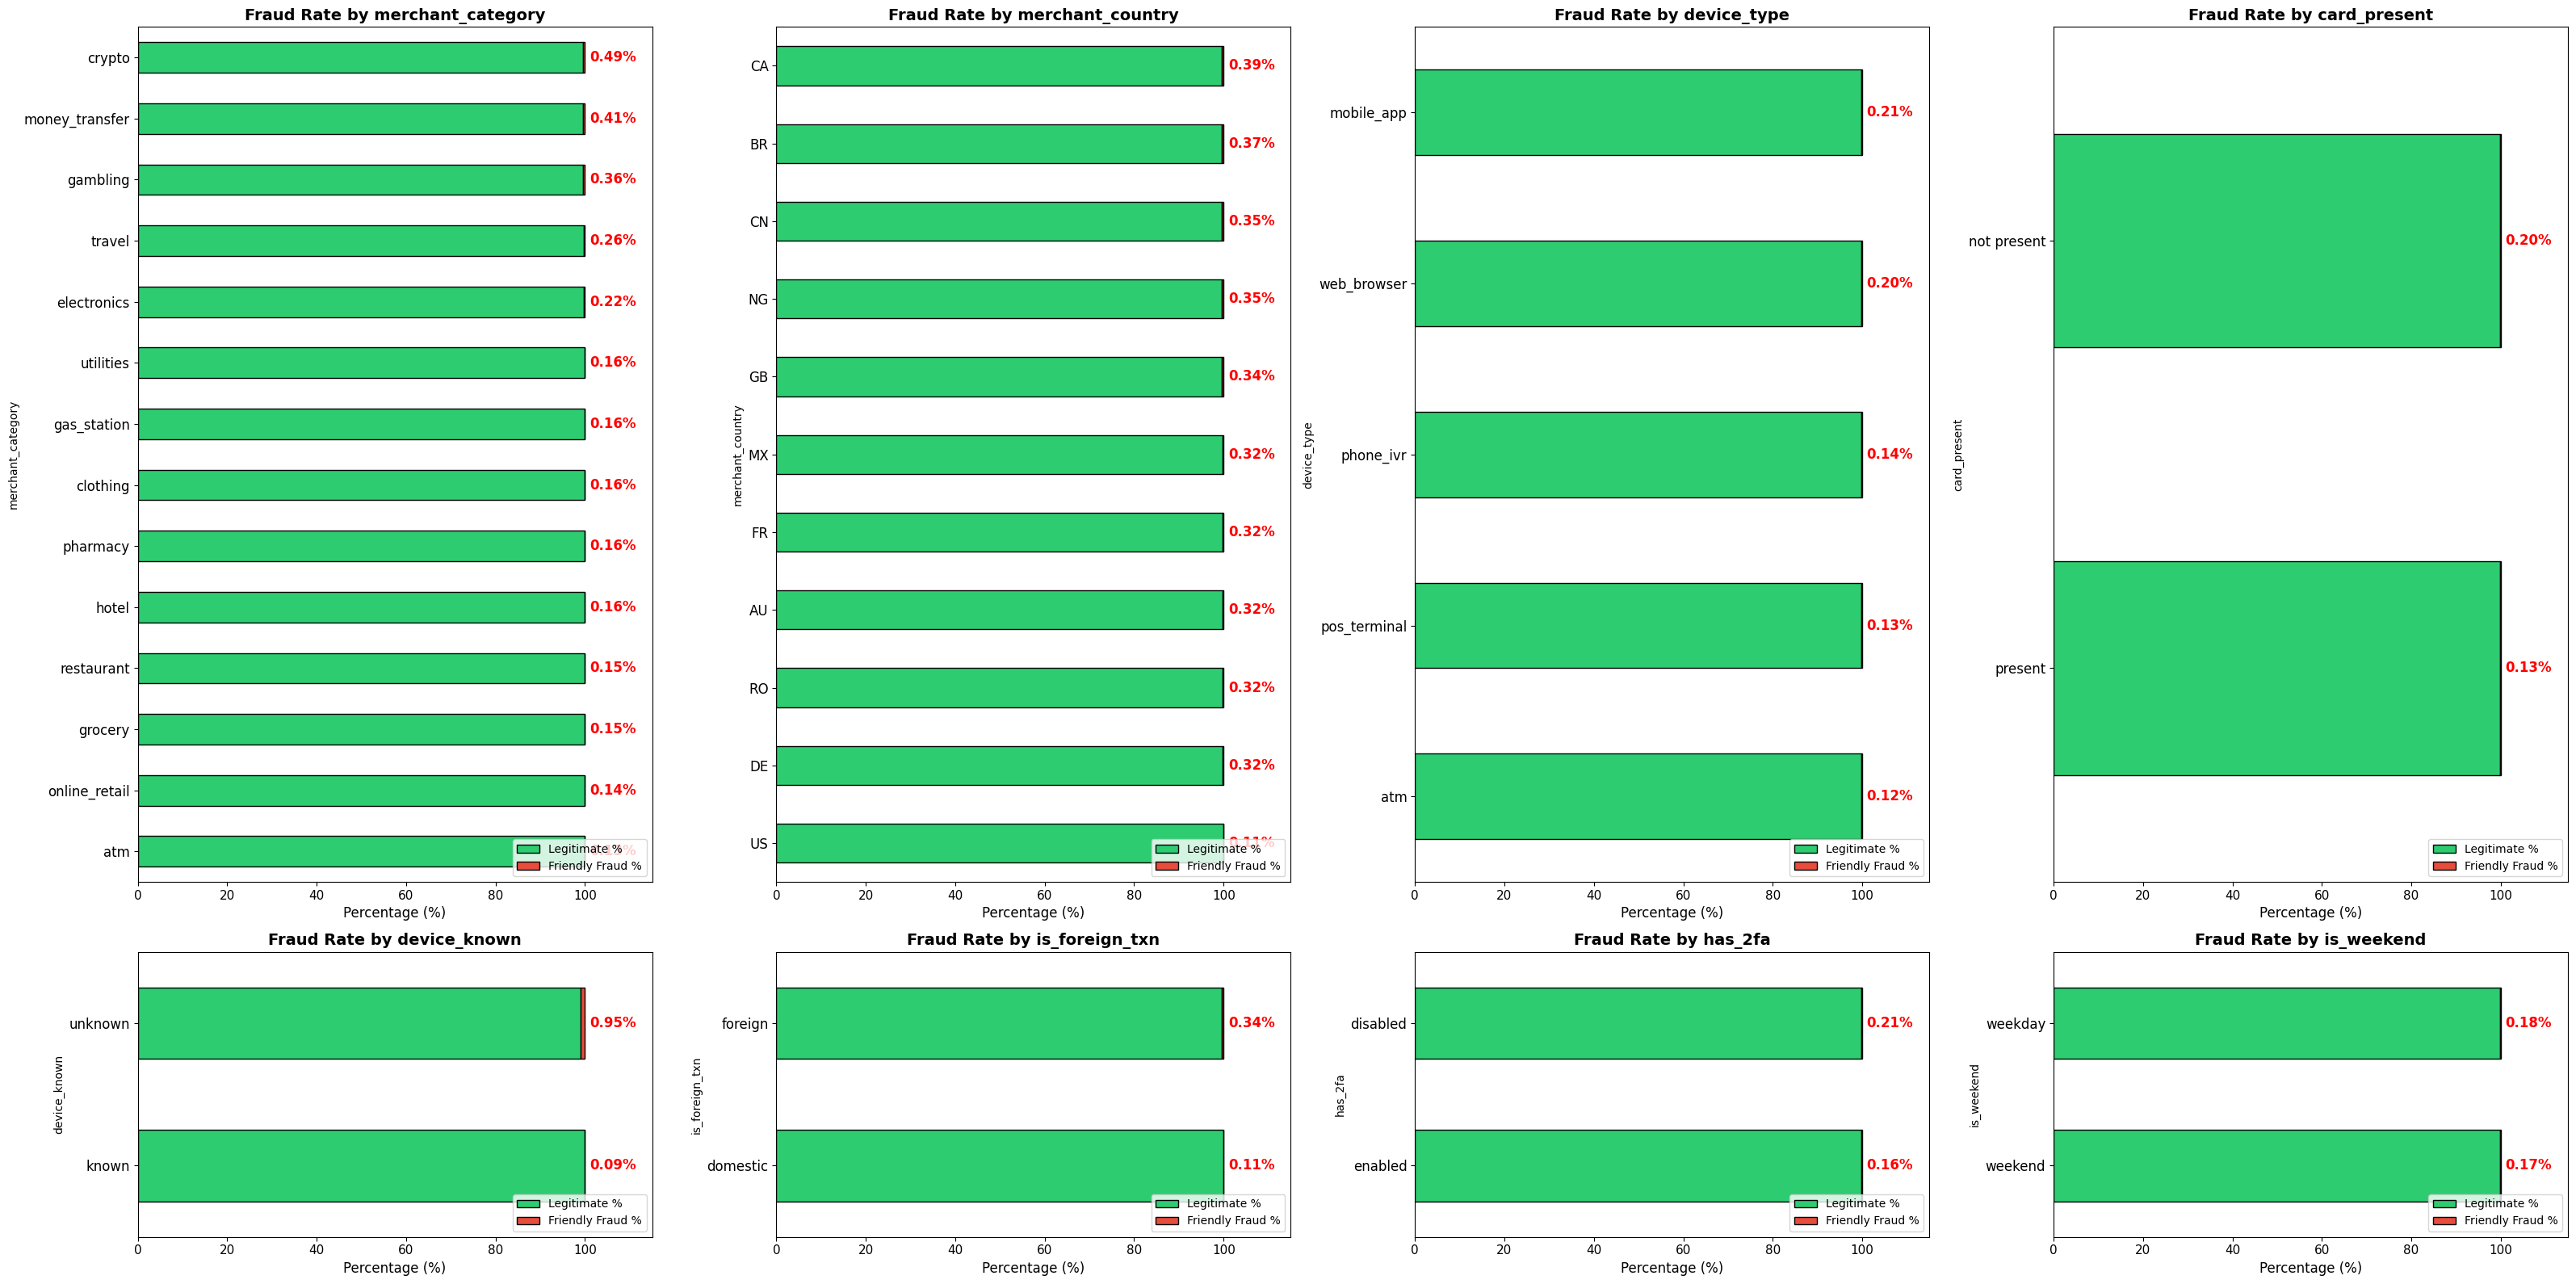

In [ ]:
#4.1.4 Categorical Features Analysis
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

cat_features = ['merchant_category', 'merchant_country', 'device_type', 'card_present',
                'device_known', 'is_foreign_txn', 'has_2fa', 'is_weekend']

fig = plt.figure(figsize=(32, 16))
gs = gridspec.GridSpec(2, 4, figure=fig, height_ratios=[3, 1])
axes = [fig.add_subplot(gs[r, c]) for r in range(2) for c in range(4)]

for idx, feat in enumerate(cat_features):
    ct = pd.crosstab(df[feat], df['is_friendly_fraud'], normalize='index') * 100
    ct.columns = ['Legitimate %', 'Friendly Fraud %']
    ct = ct.sort_values('Friendly Fraud %', ascending=True)

    ct.plot(kind='barh', stacked=True, ax=axes[idx],
            color=['#2ecc71', '#e74c3c'], edgecolor='black')
    axes[idx].set_title(f'Fraud Rate by {feat}', fontweight='bold', fontsize=14)
    axes[idx].set_xlabel('Percentage (%)', fontsize=12)
    axes[idx].set_xlim(0, 115)
    axes[idx].legend(loc='lower right', fontsize=10)
    axes[idx].tick_params(axis='x', labelsize=11)
    axes[idx].tick_params(axis='y', labelsize=12)

    for i, (name, row) in enumerate(ct.iterrows()):
        axes[idx].text(101, i, f"{row['Friendly Fraud %']:.2f}%",
                       va='center', fontsize=12, color='red', fontweight='bold')

plt.tight_layout()
plt.show()

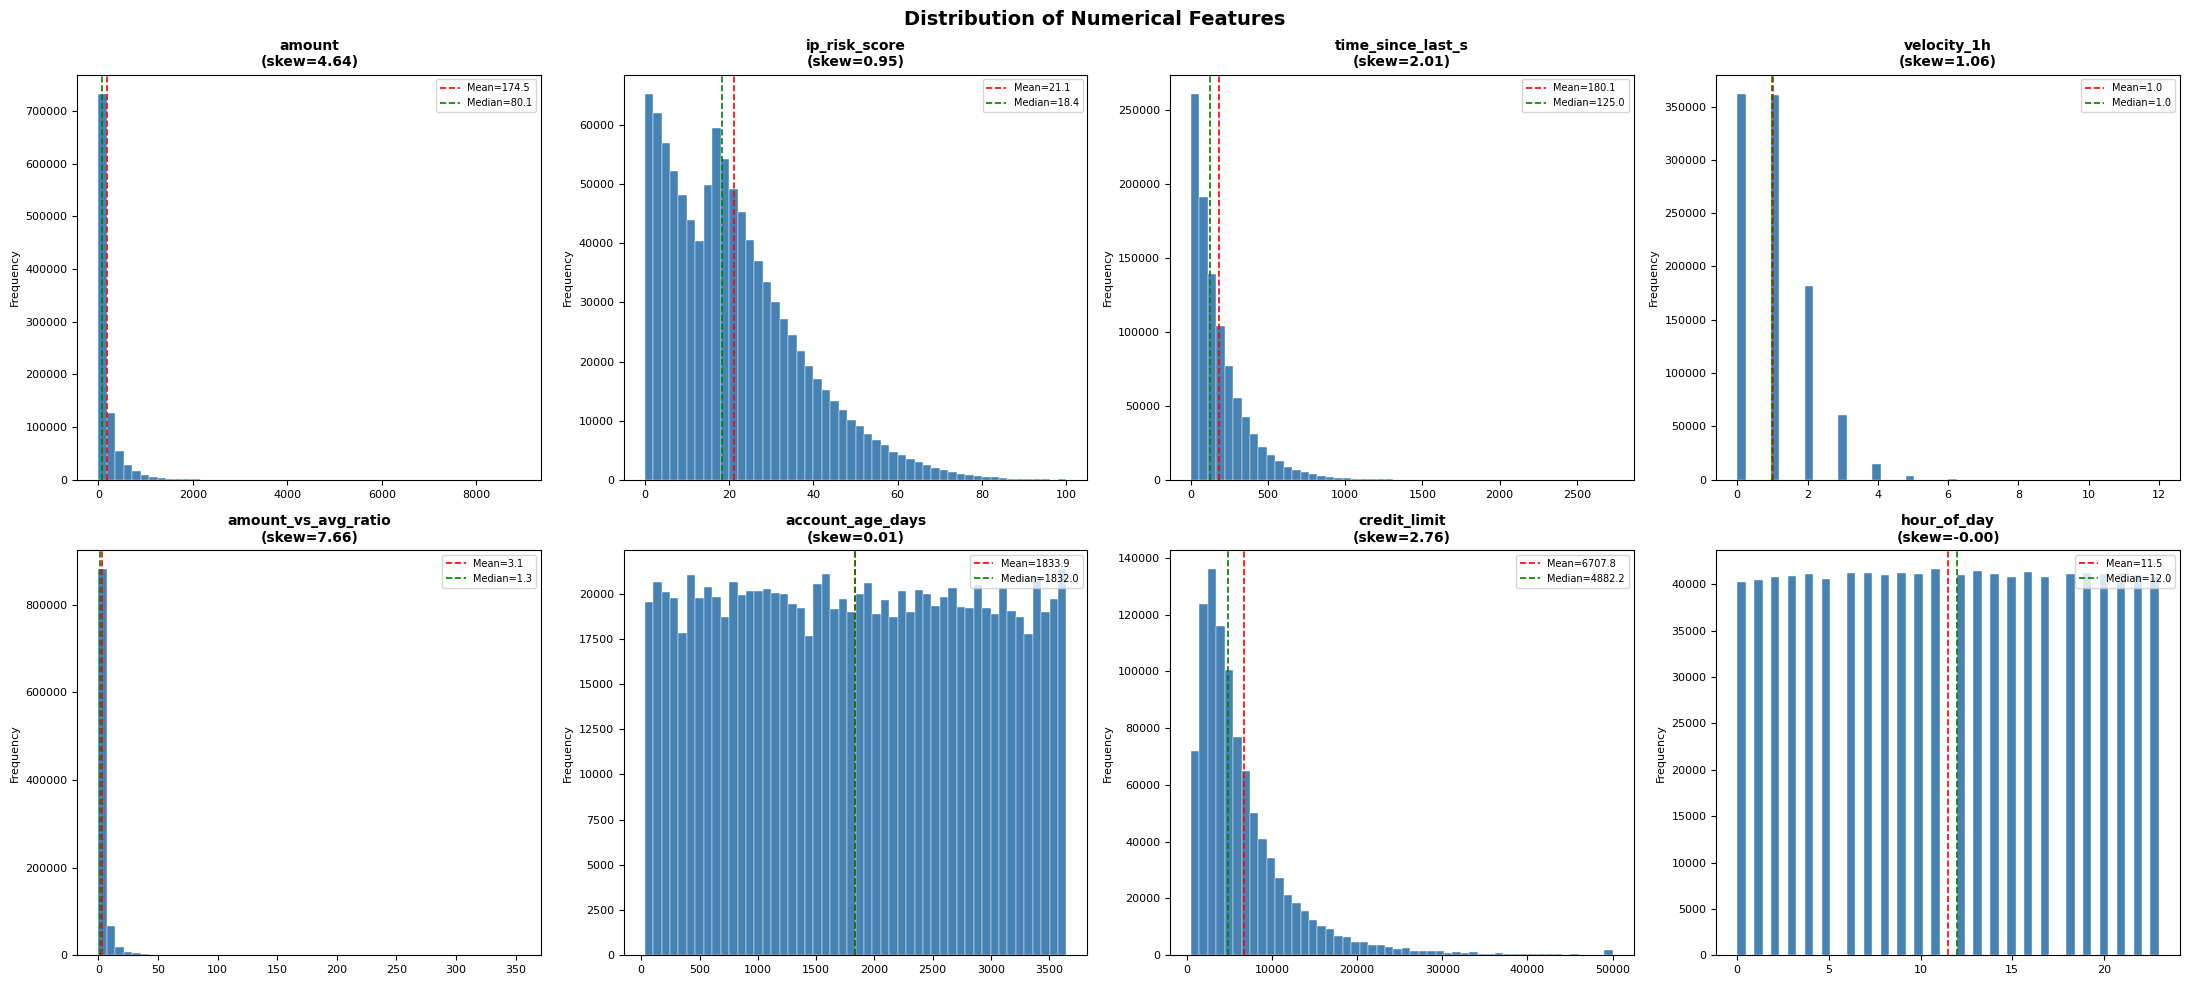

In [ ]:
#4.1.5 Numerical Feature Analysis
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

num_features = ['amount', 'ip_risk_score', 'time_since_last_s', 'velocity_1h',
                'amount_vs_avg_ratio', 'account_age_days', 'credit_limit', 'hour_of_day']

fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes = axes.flatten()

fig.suptitle('Distribution of Numerical Features', fontweight='bold', fontsize=14)

for idx, feat in enumerate(num_features):
    skew = df[feat].skew()
    mean_val = df[feat].mean()
    median_val = df[feat].median()

    axes[idx].hist(df[feat].dropna(), bins=50, color='steelblue', edgecolor='white', linewidth=0.3)
    axes[idx].axvline(mean_val, color='red', linestyle='--', linewidth=1.2, label=f'Mean={mean_val:.1f}')
    axes[idx].axvline(median_val, color='green', linestyle='--', linewidth=1.2, label=f'Median={median_val:.1f}')

    axes[idx].set_title(f'{feat}\n(skew={skew:.2f})', fontsize=10, fontweight='bold')
    axes[idx].set_xlabel('')
    axes[idx].set_ylabel('Frequency', fontsize=8)
    axes[idx].legend(fontsize=7)
    axes[idx].tick_params(labelsize=8)

plt.tight_layout()
plt.show()

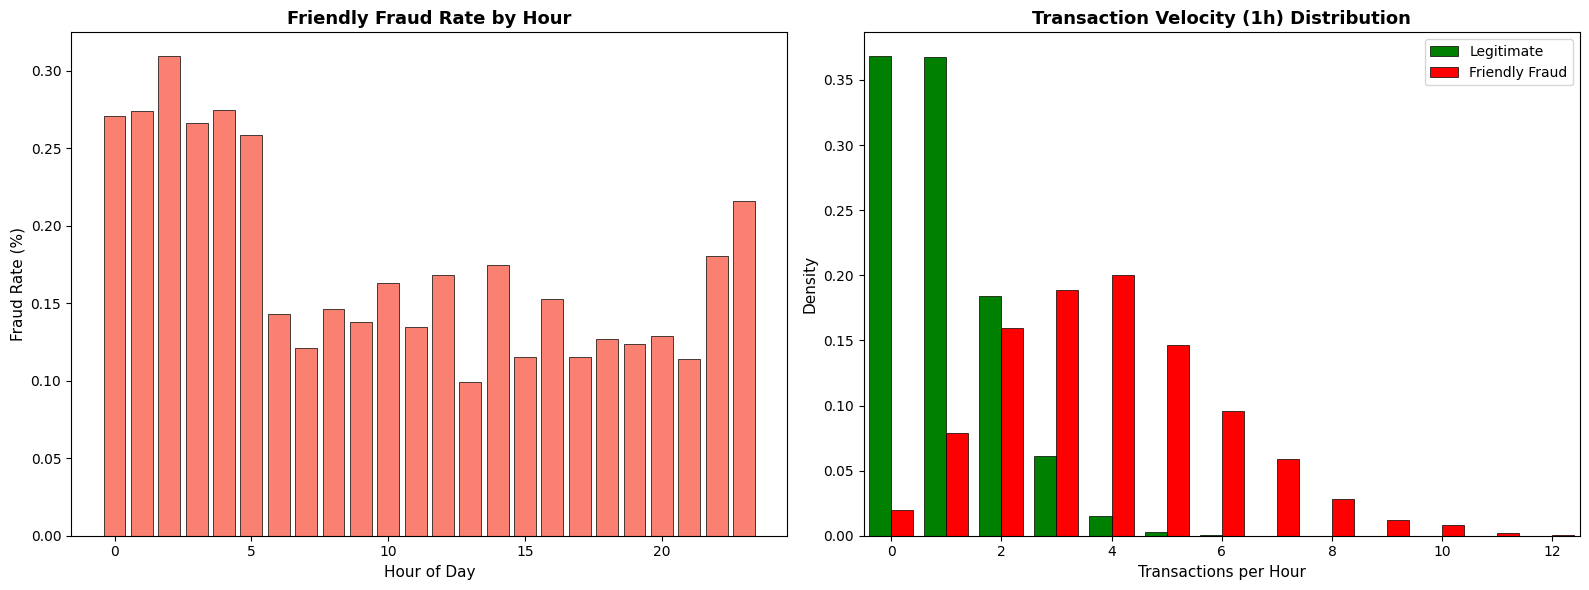

In [ ]:
#4.1.6
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Plot 1: Friendly Fraud Rate by Hour ---
fraud_by_hour = df.groupby('hour_of_day')['is_friendly_fraud'].mean() * 100

axes[0].bar(fraud_by_hour.index, fraud_by_hour.values, color='salmon', edgecolor='black', linewidth=0.5)
axes[0].set_title('Friendly Fraud Rate by Hour', fontweight='bold', fontsize=13)
axes[0].set_xlabel('Hour of Day', fontsize=11)
axes[0].set_ylabel('Fraud Rate (%)', fontsize=11)
axes[0].tick_params(labelsize=10)

# --- Plot 2: Transaction Velocity (1h) Distribution ---
legit = df[df['is_friendly_fraud'] == 0]['velocity_1h']
fraud = df[df['is_friendly_fraud'] == 1]['velocity_1h']

max_val = int(df['velocity_1h'].max())
# bins = np.arange(0, max_val + 2) - 0.2

axes[1].bar(np.arange(0, max_val + 1) - 0.2,
            [len(legit[legit == v]) / len(legit) for v in range(max_val + 1)],
            width=0.4, color='green', label='Legitimate', edgecolor='black', linewidth=0.5)
axes[1].bar(np.arange(0, max_val + 1) + 0.2,
            [len(fraud[fraud == v]) / len(fraud) for v in range(max_val + 1)],
            width=0.4, color='red', label='Friendly Fraud', edgecolor='black', linewidth=0.5)

axes[1].set_title('Transaction Velocity (1h) Distribution', fontweight='bold', fontsize=13)
axes[1].set_xlabel('Transactions per Hour', fontsize=11)
axes[1].set_ylabel('Density', fontsize=11)
axes[1].legend(fontsize=10)
axes[1].tick_params(labelsize=10)
axes[1].set_xlim(-0.5, 12.5)

plt.tight_layout()
plt.show()

/tmp/ipykernel_2958/449644556.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[idx].boxplot(
/tmp/ipykernel_2958/449644556.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[idx].boxplot(
/tmp/ipykernel_2958/449644556.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[idx].boxplot(
/tmp/ipykernel_2958/449644556.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = axes[idx].boxplot(
/tmp/ipykernel_2958/449644556.py:19: MatplotlibDeprecationWarning: The '

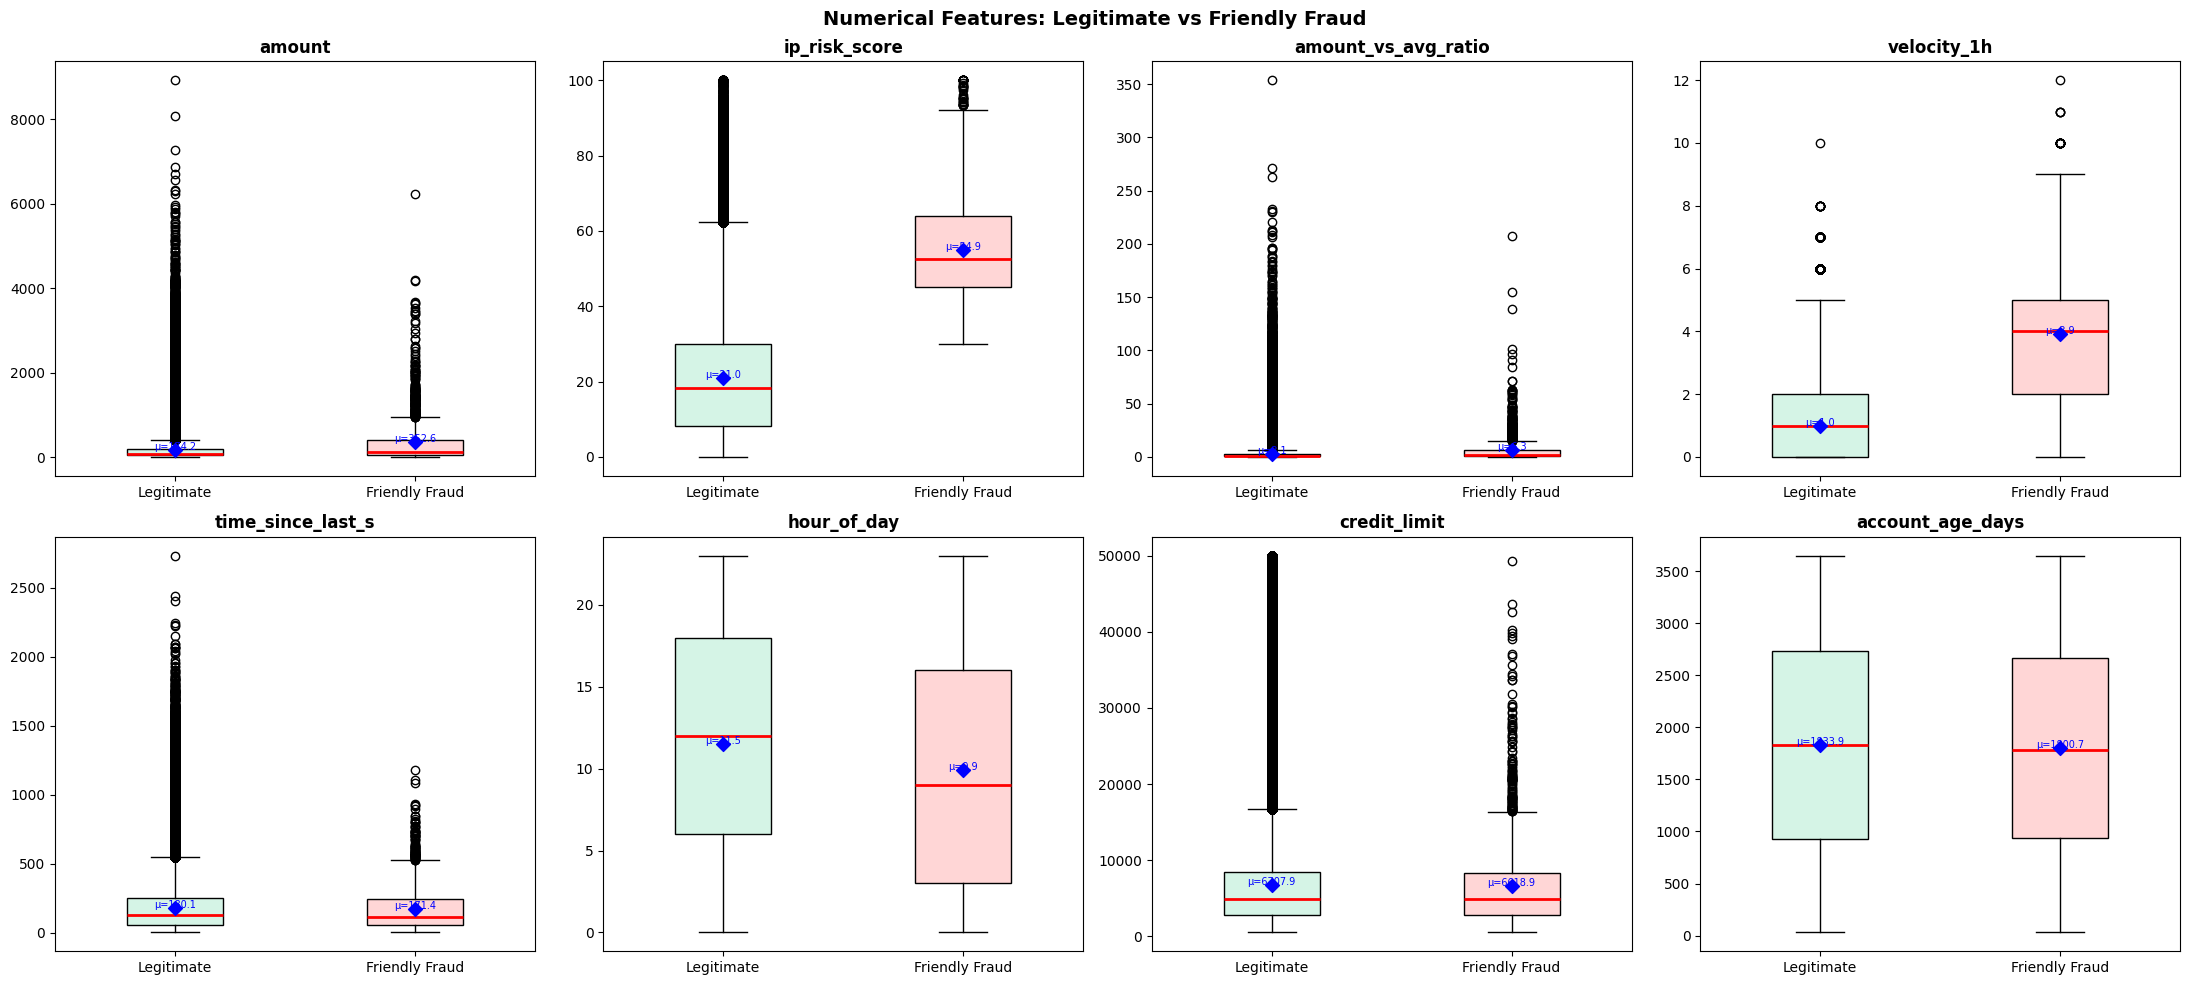

In [ ]:
#4.1.7
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel('/content/sample_data/friendly_fraud_only.xlsx')
df['is_friendly_fraud'] = (df['fraud_pattern'] == 'friendly_fraud').astype(int)

key_features = ['amount', 'ip_risk_score','amount_vs_avg_ratio',
                'velocity_1h', 'time_since_last_s',
                'hour_of_day', 'credit_limit', 'account_age_days']

fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes = axes.flatten()

for idx, feat in enumerate(key_features):
    data_leg = df[df['is_friendly_fraud'] == 0][feat]
    data_fr = df[df['is_friendly_fraud'] == 1][feat]

    bp = axes[idx].boxplot(
        [data_leg, data_fr],
        labels=['Legitimate', 'Friendly Fraud'],
        patch_artist=True,
        widths=0.4,
        medianprops=dict(color='red', linewidth=2))
    bp['boxes'][0].set_facecolor('#d5f4e6')
    bp['boxes'][1].set_facecolor('#ffd6d6')

    m_l = data_leg.mean()
    m_f = data_fr.mean()
    axes[idx].scatter([1, 2], [m_l, m_f], color='blue', zorder=5, marker='D', s=50)
    axes[idx].annotate(f'\u03bc={m_l:.1f}', (1, m_l), fontsize=7, color='blue', ha='center')
    axes[idx].annotate(f'\u03bc={m_f:.1f}', (2, m_f), fontsize=7, color='blue', ha='center')

    axes[idx].set_title(feat, fontweight='bold')

plt.suptitle('Numerical Features: Legitimate vs Friendly Fraud', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

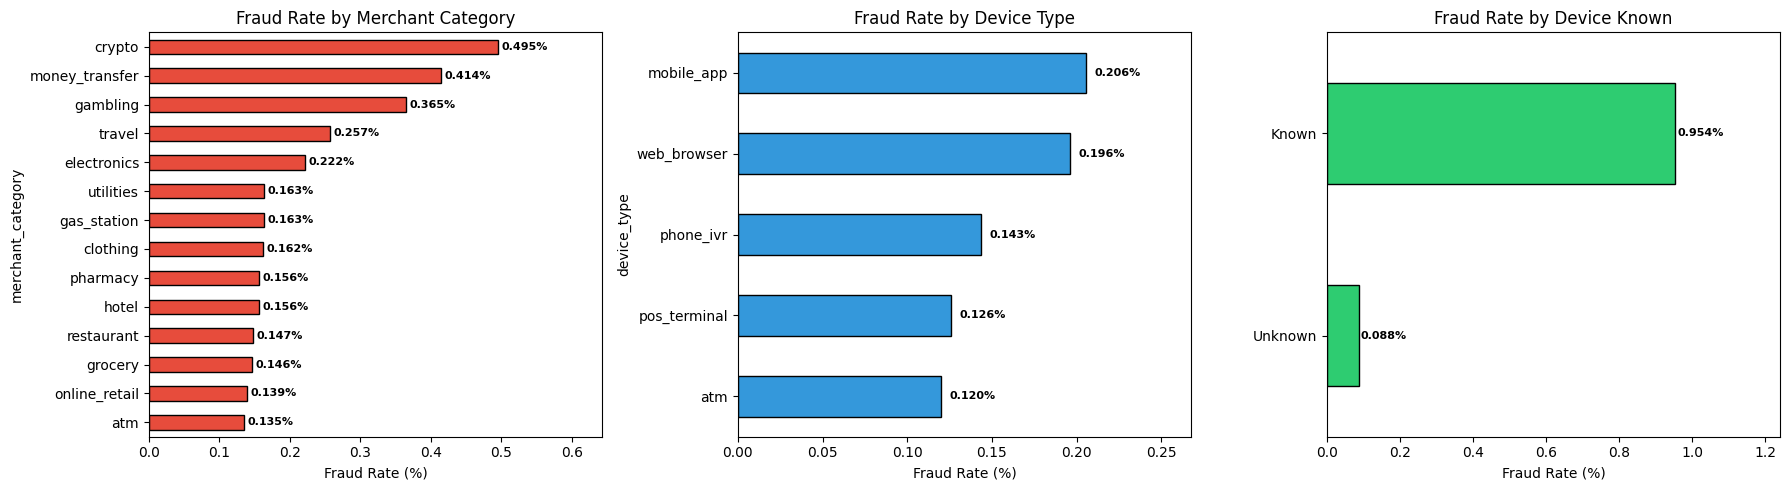

In [ ]:
#4.1.7.2 Categorical features
import matplotlib.pyplot as plt
import pandas as pd

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Merchant Category
fraud_rate = df.groupby('merchant_category')['is_friendly_fraud'].mean() * 100
fraud_rate = fraud_rate.sort_values(ascending=True)
fraud_rate.plot(kind='barh', ax=axes[0], color='#e74c3c', edgecolor='black')
for i, v in enumerate(fraud_rate.values):
    axes[0].text(v + 0.005, i, f'{v:.3f}%', va='center', fontweight='bold', fontsize=8)
axes[0].set_title('Fraud Rate by Merchant Category')
axes[0].set_xlabel('Fraud Rate (%)')
axes[0].set_xlim(0, fraud_rate.max() * 1.3)

# 2. Device Type
fraud_rate2 = df.groupby('device_type')['is_friendly_fraud'].mean() * 100
fraud_rate2 = fraud_rate2.sort_values(ascending=True)
fraud_rate2.plot(kind='barh', ax=axes[1], color='#3498db', edgecolor='black')
for i, v in enumerate(fraud_rate2.values):
    axes[1].text(v + 0.005, i, f'{v:.3f}%', va='center', fontweight='bold', fontsize=8)
axes[1].set_title('Fraud Rate by Device Type')
axes[1].set_xlabel('Fraud Rate (%)')
axes[1].set_xlim(0, fraud_rate2.max() * 1.3)

# 3. Device Known
fraud_rate3 = df.groupby('device_known')['is_friendly_fraud'].mean() * 100
fraud_rate3.index = ['Unknown', 'Known']
fraud_rate3 = fraud_rate3.sort_values(ascending=True)
fraud_rate3.plot(kind='barh', ax=axes[2], color='#2ecc71', edgecolor='black')
for i, v in enumerate(fraud_rate3.values):
    axes[2].text(v + 0.005, i, f'{v:.3f}%', va='center', fontweight='bold', fontsize=8)
axes[2].set_title('Fraud Rate by Device Known')
axes[2].set_xlabel('Fraud Rate (%)')
axes[2].set_xlim(0, fraud_rate3.max() * 1.3)

plt.tight_layout()
plt.show()

In [ ]:
#4.2.1
from scipy.stats import mannwhitneyu

num_cols = ['ip_risk_score', 'velocity_1h', 'amount', 'amount_vs_avg_ratio',
            'hour_of_day', 'time_since_last_s', 'account_age_days', 'credit_limit']

legit = df[df['is_friendly_fraud'] == 0]
fraud = df[df['is_friendly_fraud'] == 1]

results = []
for col in num_cols:
    leg_vals = legit[col].dropna()
    fra_vals = fraud[col].dropna()

    stat, p = mannwhitneyu(leg_vals, fra_vals, alternative='two-sided')

    # Effect size
    n1, n2 = len(leg_vals), len(fra_vals)
    r = abs(1 - (2 * stat) / (n1 * n2))

    m_l = leg_vals.mean()
    m_f = fra_vals.mean()
    diff = (m_f - m_l) / m_l * 100

    results.append({
        'Feature': col,
        'U-Statistic': f'{stat:,.0f}',
        'p-value': '<0.001' if p < 0.001 else f'{p:.3f}',
        'Sig.?': 'Yes' if p < 0.05 else 'No',
        'Effect (r)': f'{r:.3f}', #Rank-biserial correlation
        'Mean Legit': f'{m_l:.2f}',
        'Mean Fraud': f'{m_f:.2f}',
        'Diff %': f'{diff:+.1f}'
    })

import pandas as pd
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

            Feature U-Statistic p-value Sig.? Effect (r) Mean Legit Mean Fraud Diff %
      ip_risk_score 109,699,300  <0.001   Yes      0.871      21.02      54.91 +161.3
        velocity_1h 154,167,728  <0.001   Yes      0.818       1.00       3.93 +293.3
             amount 666,171,912  <0.001   Yes      0.215     174.21     352.61 +102.4
amount_vs_avg_ratio 678,982,762  <0.001   Yes      0.200       3.13       6.31 +101.9
        hour_of_day 961,102,670  <0.001   Yes      0.133      11.52       9.93  -13.8
  time_since_last_s 863,653,962   0.190    No      0.018     180.10     171.44   -4.8
   account_age_days 863,776,518   0.187    No      0.018    1833.94    1800.66   -1.8
       credit_limit 850,168,812   0.868    No      0.002    6707.91    6618.91   -1.3


In [ ]:
#4.2.2
from scipy.stats import chi2_contingency
import pandas as pd
import numpy as np

cat_features = ['device_known', 'merchant_country', 'is_foreign_txn', 'merchant_category',
                'device_type', 'card_present', 'has_2fa', 'is_weekend']

results = []
for feat in cat_features:
    ct = pd.crosstab(df[feat], df['is_friendly_fraud'])
    chi2, p, dof, _ = chi2_contingency(ct)

    # Cramer's V
    n = ct.sum().sum()
    k = min(ct.shape) - 1
    cramers_v = np.sqrt(chi2 / (n * k))

    results.append({
        'Feature': feat,
        'Chi²': round(chi2, 2),
        'p-value': '<0.001' if p < 0.001 else round(p, 3),
        'Significant': 'Yes' if p < 0.05 else 'No',
        "Cramer's V": round(cramers_v, 3)
    })

chi2_df = pd.DataFrame(results).sort_values('Chi²', ascending=False)
print(chi2_df.to_string(index=False))

          Feature    Chi² p-value Significant  Cramer's V
     device_known 3822.90  <0.001         Yes       0.062
 merchant_country  622.74  <0.001         Yes       0.025
   is_foreign_txn  610.24  <0.001         Yes       0.025
merchant_category  287.34  <0.001         Yes       0.017
      device_type   75.58  <0.001         Yes       0.009
     card_present   73.61  <0.001         Yes       0.009
          has_2fa   40.39  <0.001         Yes       0.006
       is_weekend    0.92   0.338          No       0.001


In [ ]:
# 4.3 ARM
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

#  5 Numerical features
df_a = pd.DataFrame()
df_a['amount'] = pd.cut(df['amount'], bins=[0, 100, 500, 100000],
                         labels=['Amount_Low', 'Amount_Medium', 'Amount_High']).astype(str)
df_a['ip_risk'] = pd.cut(df['ip_risk_score'], bins=[-1, 30, 60, 101],
                          labels=['IPRisk_Low', 'IPRisk_Medium', 'IPRisk_High']).astype(str)
df_a['velocity'] = pd.cut(df['velocity_1h'], bins=[-1, 1, 3, 100],
                            labels=['Velocity_Low', 'Velocity_Med', 'Velocity_High']).astype(str)
df_a['ratio'] = pd.cut(df['amount_vs_avg_ratio'], bins=[-0.1, 2, 10, 1000],
                         labels=['Ratio_Low', 'Ratio_Medium', 'Ratio_High']).astype(str)
df_a['hour'] = pd.cut(df['hour_of_day'], bins=[-1, 6, 12, 18, 24],
                       labels=['Night', 'Morning', 'Afternoon', 'Evening']).astype(str)

# 6 Categorical features
df_a['card'] = df['card_present'].map({0: 'CardNotPresent', 1: 'CardPresent'}).astype(str)
df_a['dev_known'] = df['device_known'].map({0: 'UnknownDevice', 1: 'KnownDevice'}).astype(str)
df_a['foreign'] = df['is_foreign_txn'].map({0: 'Domestic', 1: 'Foreign'}).astype(str)
df_a['twofa'] = df['has_2fa'].map({0: 'No2FA', 1: 'Has2FA'}).astype(str)
df_a['device'] = np.where(df['device_type'].isin(['mobile_app', 'web_browser']),
                           'Digital', 'Physical').astype(str)
df_a['merchant'] = 'Merchant_' + df['merchant_category'].astype(str)

#  Fraud label
df_a['fraud'] = df['is_friendly_fraud'].map({0: 'Legit', 1: 'FRAUD'}).astype(str)

# Just do it on a sampl with all fraud + 8000 legit transactions
fraud_rows = df_a[df_a['fraud'] == 'FRAUD']
legit_rows = df_a[df_a['fraud'] == 'Legit'].sample(8000, random_state=42)
df_sample = pd.concat([fraud_rows, legit_rows]).reset_index(drop=True)

# Transfer to basket format
transactions = df_sample.values.tolist()
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
basket = pd.DataFrame(te_ary, columns=te.columns_)

#  Run Apriori
freq = apriori(basket, min_support=0.005, use_colnames=True, max_len=4)
rules = association_rules(freq, metric='confidence', min_threshold=0.01,
                          num_itemsets=len(freq))

# Filter rules FRAUD + remove duplicate + just take top 10
fraud_rules = rules[rules['consequents'].apply(lambda x: 'FRAUD' in str(x))]
fraud_rules = fraud_rules.sort_values('lift', ascending=False)
fraud_rules['ante_str'] = fraud_rules['antecedents'].apply(lambda x: ' + '.join(sorted(x)))
fraud_rules = fraud_rules.drop_duplicates(subset='ante_str', keep='first').head(10)

# Display
result = fraud_rules[['ante_str', 'confidence', 'lift']].copy()
result.columns = ['Antecedent Pattern', 'Confidence', 'Lift']
print(result.round(4).to_string(index=False))

                     Antecedent Pattern  Confidence    Lift
            Amount_High + Velocity_High      0.2193 22.6904
        Merchant_crypto + Velocity_High      0.8621 22.2400
             Ratio_High + Velocity_High      0.8168 21.0710
              Amount_High + IPRisk_High      0.6279 20.5624
Merchant_money_transfer + Velocity_High      0.7763 20.0277
               IPRisk_High + Ratio_High      0.7714 19.9016
             IPRisk_Medium + Ratio_High      0.1619 16.7520
        IPRisk_Medium + Merchant_crypto      0.5100 16.7012
            Amount_High + IPRisk_Medium      0.1544 15.9786
IPRisk_Medium + Merchant_money_transfer      0.5462 14.0899


In [ ]:
# Compare 2 scalers
import pandas as pd, time
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler, RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import f1_score, recall_score, precision_score, roc_auc_score
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
import warnings; warnings.filterwarnings('ignore')

# 1. Read file + and use a sample with 150k legit transactions
df = pd.read_excel('/content/sample_data/friendly_fraud_only.xlsx')
df['is_friendly_fraud'] = (df['fraud_pattern'] == 'friendly_fraud').astype(int)

fraud_df = df[df['is_friendly_fraud'] == 1]
legit_df = df[df['is_friendly_fraud'] == 0].sample(n=150000, random_state=42)
df = pd.concat([fraud_df, legit_df]).sample(frac=1, random_state=42).reset_index(drop=True)

# 2. Prepare + Split
df_ml = df.copy()
for col in ['merchant_category', 'device_type', 'merchant_country']:
    df_ml[col] = LabelEncoder().fit_transform(df_ml[col].astype(str))

feature_columns = ['amount','ip_risk_score','time_since_last_s','velocity_1h',
    'amount_vs_avg_ratio','account_age_days','credit_limit','hour_of_day',
    'day_of_week','is_weekend','card_present','device_known','is_foreign_txn',
    'has_2fa','mcc_code','merchant_category','device_type','merchant_country']
X, y = df_ml[feature_columns], df_ml['is_friendly_fraud']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Train 3 models × 2 scalers
def models():
    return {
        'MLP Neural Net':      MLPClassifier(random_state=42, max_iter=300),
        'KNN':                 KNeighborsClassifier(n_jobs=-1),
        'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000, n_jobs=-1),
    }

results = {}
for sname, scaler in {'Standard': StandardScaler(), 'Robust': RobustScaler()}.items():
    X_tr = scaler.fit_transform(X_train)
    X_te = scaler.transform(X_test)
    rows = []
    # print(f"── {sname}Scaler ──")
    for name, m in models().items():
        # t = time.time();
        m.fit(X_tr, y_train)
        p = m.predict(X_te)
        rows.append({'Model': name,
            'Precision': round(precision_score(y_test, p), 3),
            'Recall':    round(recall_score(y_test, p), 3),
            'F1-Score':  round(f1_score(y_test, p), 3),
            'ROC-AUC':   round(roc_auc_score(y_test, m.predict_proba(X_te)[:,1]), 3)})
    results[sname] = pd.DataFrame(rows)

# Print the result
for sname in ['Standard', 'Robust']:
    print(f"\n{sname.upper()} SCALER\n")
    print(results[sname].to_string(index=False))


── StandardScaler ──
── RobustScaler ──

STANDARD SCALER

              Model  Precision  Recall  F1-Score  ROC-AUC
     MLP Neural Net      0.745   0.559     0.639    0.986
                KNN      0.872   0.357     0.506    0.817
Logistic Regression      0.821   0.545     0.655    0.984

ROBUST SCALER

              Model  Precision  Recall  F1-Score  ROC-AUC
     MLP Neural Net      0.771   0.577     0.660    0.988
                KNN      0.909   0.261     0.405    0.803
Logistic Regression      0.825   0.545     0.656    0.984


In [ ]:
# Machine Learning model training
import pandas as pd, numpy as np, time
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score)
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
import warnings; warnings.filterwarnings('ignore')

# Param with sample of 50k legit transactions
Sample_legit    = 50000      # Before split
Target_realistic_rate = 0.00175    # 0.175% = real fraud rate

# Read the file + Encode
df = pd.read_excel('/content/sample_data/friendly_fraud_only.xlsx')
df['is_friendly_fraud'] = (df['fraud_pattern'] == 'friendly_fraud').astype(int)
for col in ['merchant_category', 'device_type', 'merchant_country']:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))

feature_columns = ['amount','ip_risk_score','time_since_last_s','velocity_1h',
    'amount_vs_avg_ratio','account_age_days','credit_limit','hour_of_day',
    'day_of_week','is_weekend','card_present','device_known','is_foreign_txn',
    'has_2fa','mcc_code','merchant_category','device_type','merchant_country']

fraud = df[df['is_friendly_fraud'] == 1]
legit = df[df['is_friendly_fraud'] == 0].sample(frac=1, random_state=42).reset_index(drop=True)

# Sample 50k → Split w ratio 75/25
legit_main = legit.iloc[:Sample_legit]
data = pd.concat([fraud, legit_main]).reset_index(drop=True)
X, y = data[feature_columns], data['is_friendly_fraud']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
Xs, ys = X_te, y_te                                    # sampled test

# SMOTE (train only) + Scale
X_tr, y_tr = SMOTE(sampling_strategy=0.5, random_state=42).fit_resample(X_tr, y_tr)
sc = StandardScaler(); X_tr_s = sc.fit_transform(X_tr)

# Realistic Test: sampled test + add more legit → 0.175%
n_fraud    = int(ys.sum())
need_legit = round(n_fraud * (1 - Target_realistic_rate) / Target_realistic_rate)
extra      = need_legit - int((ys == 0).sum())
legit_extra = legit.iloc[Sample_legit:Sample_legit + extra]

Xr = pd.concat([X_te, legit_extra[feature_columns]]).reset_index(drop=True)
yr = pd.concat([y_te, legit_extra['is_friendly_fraud']]).reset_index(drop=True)
Xs_s = sc.transform(Xs); Xr_s = sc.transform(Xr)


# 8 models
models = {
    'Gradient Boosting':   GradientBoostingClassifier(random_state=42),
    'XGBoost':             XGBClassifier(random_state=42, eval_metric='logloss', use_label_encoder=False, n_jobs=-1),
    'MLP':                 MLPClassifier(random_state=42, max_iter=300),
    'Random Forest':       RandomForestClassifier(random_state=42, n_jobs=-1),
    'KNN':                 KNeighborsClassifier(n_jobs=-1),
    'Decision Tree':       DecisionTreeClassifier(random_state=42),
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000, n_jobs=-1),
    'Naive Bayes':         GaussianNB(),
}
def metrics(name, m, X, y):
    p = m.predict(X); pr = m.predict_proba(X)[:, 1]
    return {'Model': name,
        'Accuracy':  round(accuracy_score(y, p), 3),
        'Precision': round(precision_score(y, p), 3),
        'Recall':    round(recall_score(y, p), 3),
        'F1-Score':  round(f1_score(y, p), 3),
        'ROC-AUC':   round(roc_auc_score(y, pr), 3),
        'Avg Precision': round(average_precision_score(y, pr), 3)}

rs, rr = [], []
for name, m in models.items():
    # t = time.time();
    m.fit(X_tr_s, y_tr)
    rs.append(metrics(name, m, Xs_s, ys)); rr.append(metrics(name, m, Xr_s, yr))

res_s = pd.DataFrame(rs).sort_values('F1-Score', ascending=False).reset_index(drop=True)
res_r = pd.DataFrame(rr).sort_values('F1-Score', ascending=False).reset_index(drop=True)

print("Sampled set:")
print(res_s.to_string(index=False))

print("\nRealistic set:")
print(res_r.to_string(index=False))

Sampled set:
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  Avg Precision
            XGBoost     0.986      0.794   0.792     0.793    0.990          0.867
      Random Forest     0.985      0.769   0.801     0.785    0.989          0.846
  Gradient Boosting     0.981      0.677   0.843     0.751    0.991          0.872
                MLP     0.981      0.693   0.764     0.727    0.985          0.811
Logistic Regression     0.973      0.565   0.850     0.678    0.983          0.826
      Decision Tree     0.974      0.589   0.766     0.666    0.874          0.459
                KNN     0.966      0.494   0.713     0.583    0.907          0.531
        Naive Bayes     0.948      0.370   0.812     0.509    0.956          0.492

Realistic set:
              Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  Avg Precision
            XGBoost     0.991      0.141   0.792     0.240    0.989          0.498
      Random Forest     0.990      0.124   0.801     0.215

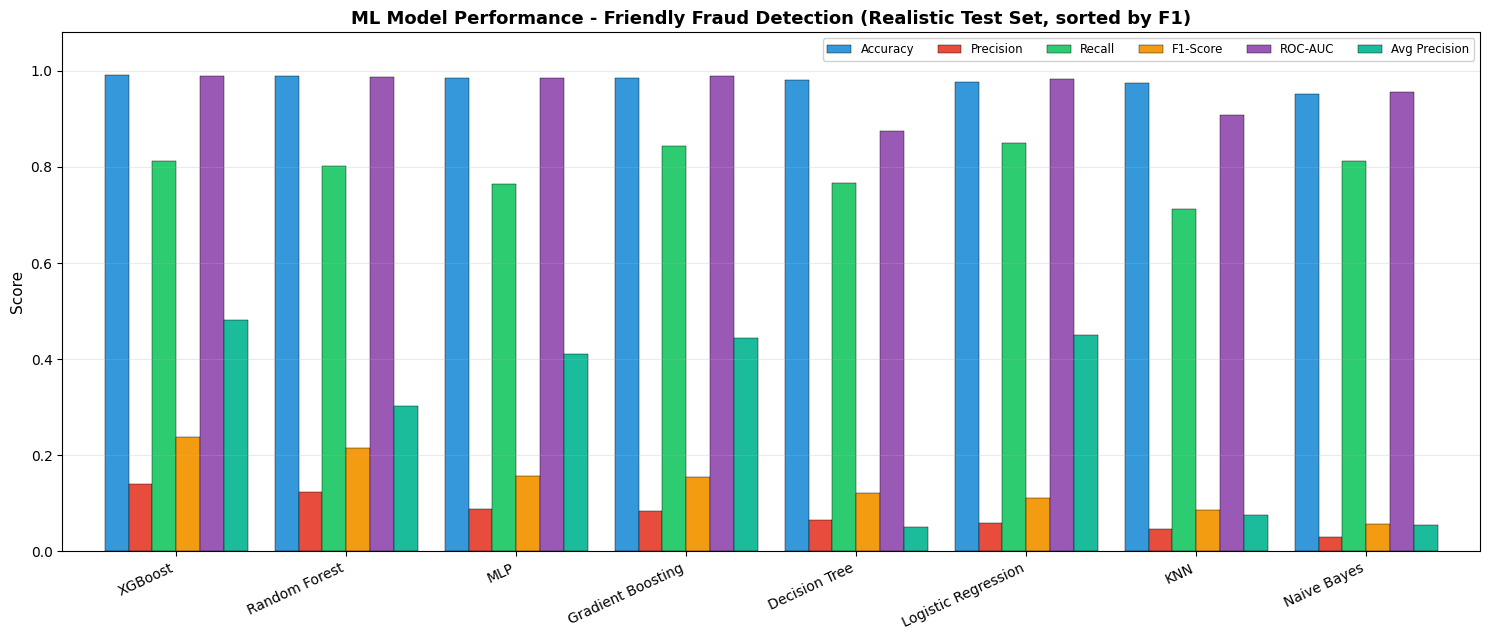

In [ ]:
# Charts for all performances sorted by model : Figure 4.7
import matplotlib.pyplot as plt

# realistic: use res_r (sorted by F1)
metrics_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'Avg Precision']
dfp = res_r.set_index('Model')[metrics_plot]   # ← res_r = realistic

colors = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12', '#9b59b6', '#1abc9c']
ax = dfp.plot(kind='bar', figsize=(15, 6.5), width=0.84,
              edgecolor='black', linewidth=0.3, color=colors)

ax.set_title('ML Model Performance - Friendly Fraud Detection (Realistic Test Set, sorted by F1)',
             fontweight='bold', fontsize=13)
ax.set_ylabel('Score', fontsize=11)
ax.set_ylim(0, 1.08)
ax.set_xlabel('')
ax.legend(loc='upper right', ncol=6, fontsize=8.5, framealpha=0.9)
ax.grid(axis='y', alpha=0.25)
plt.xticks(rotation=25, ha='right', fontsize=10)
plt.tight_layout()

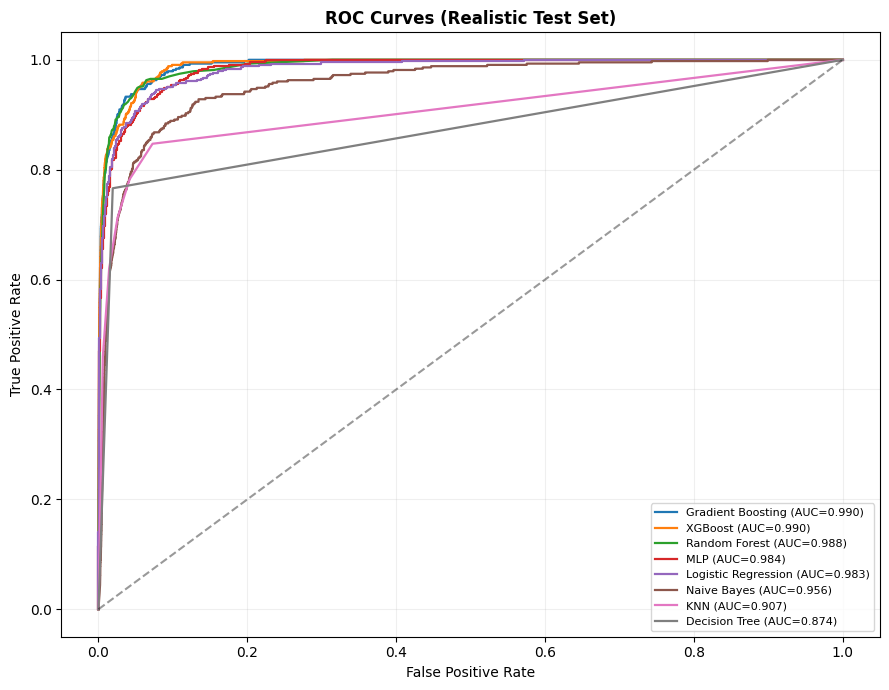

In [ ]:
# ROC for only realistic set
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

def plot_roc(test_X, test_y, title):
    # calculate AUC first then sort
    aucs = []
    for name, m in models.items():
        proba = m.predict_proba(test_X)[:, 1]
        fpr, tpr, _ = roc_curve(test_y, proba)
        aucs.append((name, fpr, tpr, auc(fpr, tpr)))
    aucs.sort(key=lambda x: x[3], reverse=True)

    plt.figure(figsize=(9, 7))
    for name, fpr, tpr, a in aucs:
        plt.plot(fpr, tpr, label=f'{name} (AUC={a:.3f})', linewidth=1.6)
    plt.plot([0, 1], [0, 1], 'k--', alpha=0.4)
    plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
    plt.title(title, fontweight='bold')
    plt.legend(loc='lower right', fontsize=8); plt.grid(alpha=0.2)
    plt.tight_layout(); plt.show()

plot_roc(Xr_s, yr, 'ROC Curves (Realistic Test Set)')

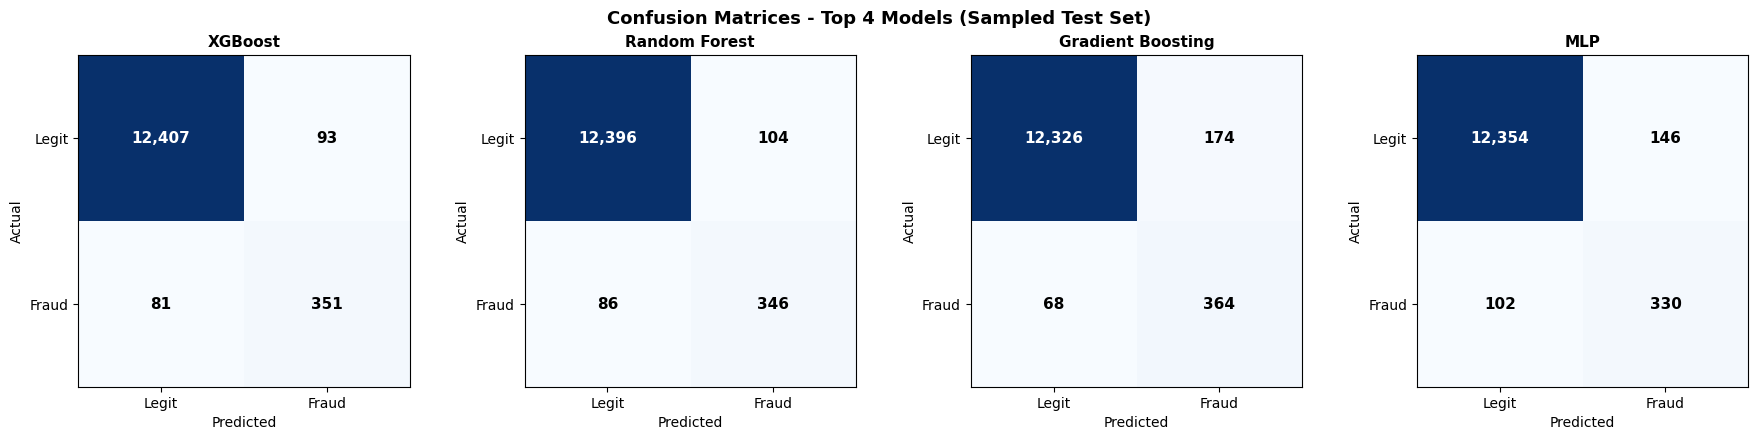

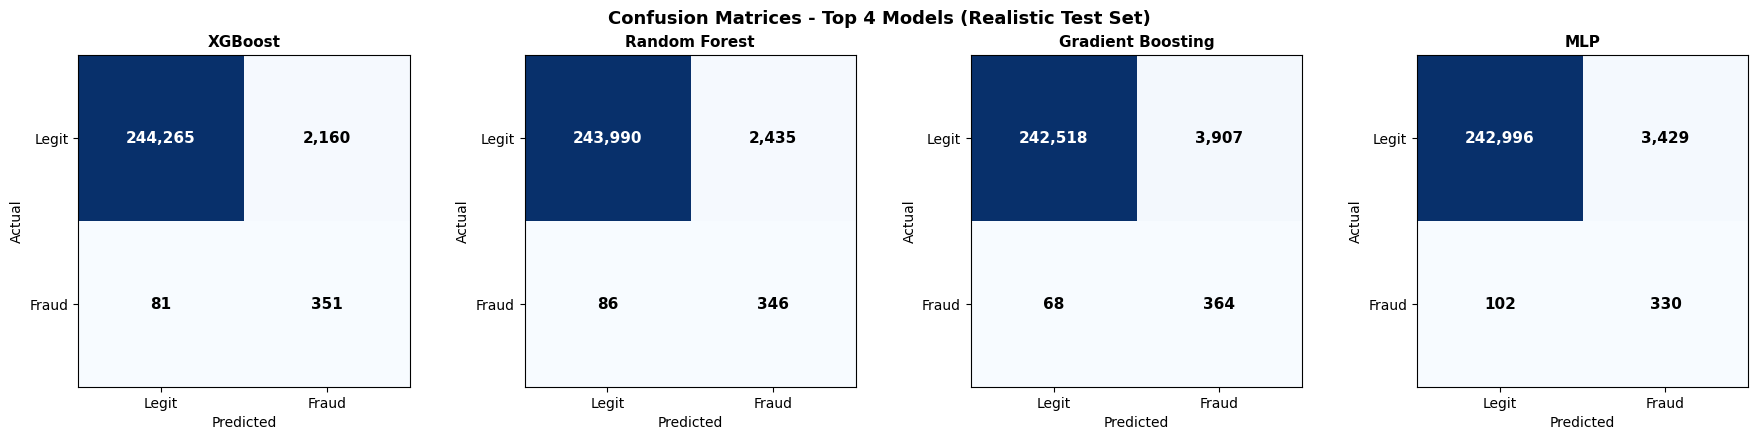

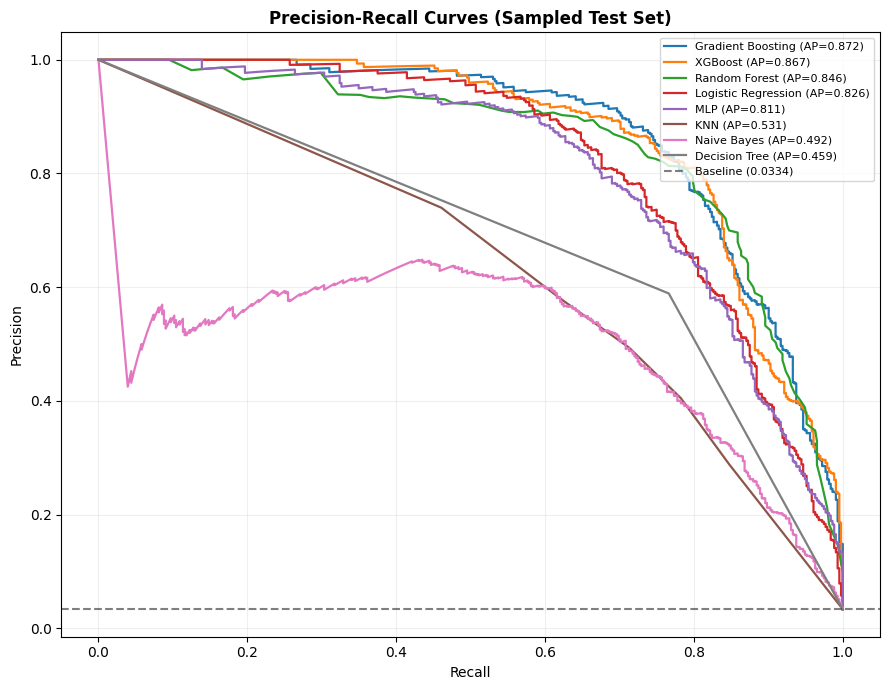

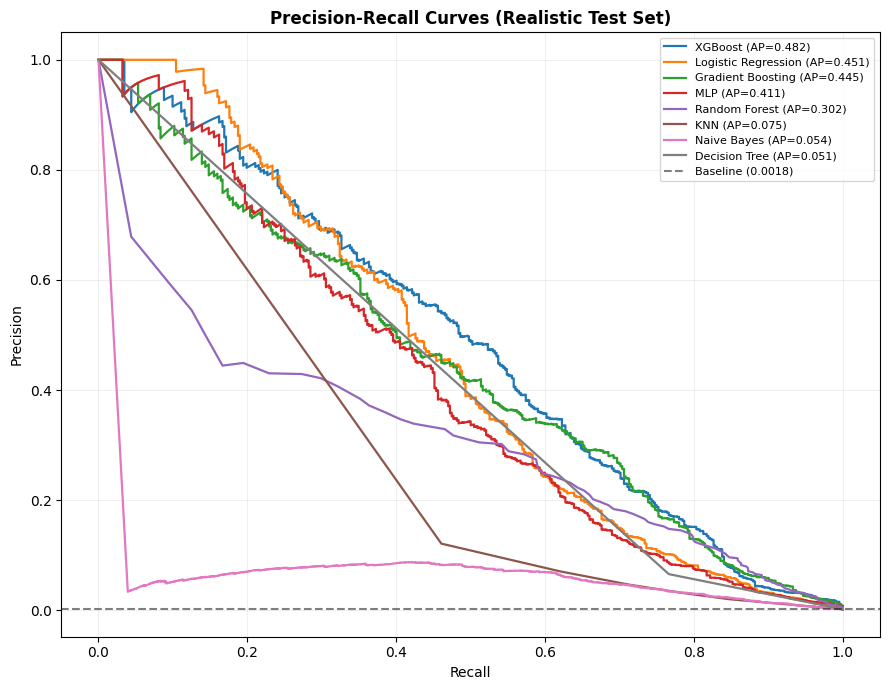

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (roc_curve, auc, precision_recall_curve,
                             average_precision_score, confusion_matrix)

# Confusion matrices, top 4 models (sampled + realistic)

# Sort top 4 order by F1 score
top4 = (res_s.sort_values(by='F1-Score', ascending=False)
          .head(4)['Model'].tolist())

def plot_cm(test_X, test_y, title, fname=None):
    fig, axes = plt.subplots(1, 4, figsize=(18, 4.3))
    for ax, name in zip(axes, top4):
        cm = confusion_matrix(test_y, models[name].predict(test_X))
        ax.imshow(cm, cmap='Blues')
        for (i, j), v in np.ndenumerate(cm):
            ax.text(j, i, f'{v:,}', ha='center', va='center',
                    color='white' if v > cm.max()/2 else 'black',
                    fontweight='bold', fontsize=11)
        ax.set_title(name, fontweight='bold', fontsize=11)
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(['Legit', 'Fraud']); ax.set_yticklabels(['Legit', 'Fraud'])
        ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
    fig.suptitle(title, fontweight='bold', fontsize=13)
    plt.tight_layout()
    plt.show()

plot_cm(Xs_s, ys, 'Confusion Matrices - Top 4 Models (Sampled Test Set)')
plot_cm(Xr_s, yr, 'Confusion Matrices - Top 4 Models (Realistic Test Set)')


# PR curves (sampled + realistic)

def plot_pr(test_X, test_y, title, fname=None):
    plt.figure(figsize=(9, 7))

    # Calculate AP for all models
    model_scores = []
    for name, m in models.items():
        proba = m.predict_proba(test_X)[:, 1]
        ap = average_precision_score(test_y, proba)
        model_scores.append((name, m, ap))

    # Sort AP descending
    model_scores.sort(key=lambda x: x[2], reverse=True)

    for name, m, ap in model_scores:
        proba = m.predict_proba(test_X)[:, 1]
        prec, rec, _ = precision_recall_curve(test_y, proba)
        plt.plot(rec, prec, label=f'{name} (AP={ap:.3f})', linewidth=1.6)

    baseline = test_y.mean()
    plt.axhline(baseline, color='k', linestyle='--', alpha=0.5,
                label=f'Baseline ({baseline:.4f})')

    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title(title, fontweight='bold')
    plt.legend(loc='upper right', fontsize=8)
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

plot_pr(Xs_s, ys, 'Precision-Recall Curves (Sampled Test Set)')
plot_pr(Xr_s, yr, 'Precision-Recall Curves (Realistic Test Set)')

In [ ]:
# Deep Learning models
import pandas as pd, numpy as np, time
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score)
from imblearn.over_sampling import SMOTE
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
import warnings; warnings.filterwarnings('ignore')

# ── Set seed
import os, random
os.environ['PYTHONHASHSEED'] = '42'
random.seed(42); np.random.seed(42)
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()

# Param
Sample_legit    = 50000
Target_realistic_rate = 0.00175

# Read file + Encode
df = pd.read_excel('/content/sample_data/friendly_fraud_only.xlsx')
df['is_friendly_fraud'] = (df['fraud_pattern'] == 'friendly_fraud').astype(int)
for col in ['merchant_category', 'device_type', 'merchant_country']:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))
feature_columns = ['amount','ip_risk_score','time_since_last_s','velocity_1h',
    'amount_vs_avg_ratio','account_age_days','credit_limit','hour_of_day',
    'day_of_week','is_weekend','card_present','device_known','is_foreign_txn',
    'has_2fa','mcc_code','merchant_category','device_type','merchant_country']
fraud = df[df['is_friendly_fraud'] == 1]
legit = df[df['is_friendly_fraud'] == 0].sample(frac=1, random_state=42).reset_index(drop=True)

# Sample w 50k → Split w ratio 75:25
legit_main = legit.iloc[:Sample_legit ]
data = pd.concat([fraud, legit_main]).reset_index(drop=True)
X, y = data[feature_columns], data['is_friendly_fraud']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
Xs, ys = X_te, y_te

# Smote (Train only) + Scale
X_tr, y_tr = SMOTE(sampling_strategy=0.5, random_state=42).fit_resample(X_tr, y_tr)
sc = StandardScaler(); X_tr_s = sc.fit_transform(X_tr)

# REALISTIC TEST Realistic test
n_fraud = int(ys.sum())
need_legit = round(n_fraud * (1 - Target_realistic_rate) / Target_realistic_rate)
extra = need_legit - int((ys == 0).sum())
legit_extra = legit.iloc[Sample_legit :Sample_legit  + extra]
Xr = pd.concat([X_te, legit_extra[feature_columns]]).reset_index(drop=True)
yr = pd.concat([y_te, legit_extra['is_friendly_fraud']]).reset_index(drop=True)
Xs_s = sc.transform(Xs); Xr_s = sc.transform(Xr)

# Reshape for sequence models
n_feat = X_tr_s.shape[1]
Xtr_seq = X_tr_s.reshape(-1, n_feat, 1)
Xs_seq  = Xs_s.reshape(-1, n_feat, 1)
Xr_seq  = Xr_s.reshape(-1, n_feat, 1)
y_tr_a, ys_a, yr_a = y_tr.values, ys.values, yr.values


# Build 5 models
def build_lstm():
    return models.Sequential([layers.Input((n_feat,1)),
        layers.LSTM(64, return_sequences=True), layers.Dropout(0.3),
        layers.LSTM(32), layers.Dropout(0.3), layers.Dense(1, activation='sigmoid')])
def build_bilstm():
    return models.Sequential([layers.Input((n_feat,1)),
        layers.Bidirectional(layers.LSTM(64, return_sequences=True)), layers.Dropout(0.3),
        layers.Bidirectional(layers.LSTM(32)), layers.Dropout(0.3), layers.Dense(1, activation='sigmoid')])
def build_gru():
    return models.Sequential([layers.Input((n_feat,1)),
        layers.GRU(64, return_sequences=True), layers.Dropout(0.3),
        layers.GRU(32), layers.Dropout(0.3), layers.Dense(1, activation='sigmoid')])
def build_cnn():
    return models.Sequential([layers.Input((n_feat,1)),
        layers.Conv1D(64, 3, padding='same', activation='relu'), layers.BatchNormalization(),
        layers.Conv1D(32, 3, padding='same', activation='relu'), layers.BatchNormalization(),
        layers.GlobalMaxPooling1D(), layers.Dense(32, activation='relu'), layers.Dropout(0.3),
        layers.Dense(1, activation='sigmoid')])
def build_dnn():
    return models.Sequential([layers.Input((n_feat,)),
        layers.Dense(128, activation='relu'), layers.BatchNormalization(), layers.Dropout(0.4),
        layers.Dense(64, activation='relu'),  layers.BatchNormalization(), layers.Dropout(0.3),
        layers.Dense(32, activation='relu'),  layers.BatchNormalization(), layers.Dropout(0.2),
        layers.Dense(1, activation='sigmoid')])

architectures = {
    'LSTM':   (build_lstm,   Xtr_seq, Xs_seq, Xr_seq),
    'BiLSTM': (build_bilstm, Xtr_seq, Xs_seq, Xr_seq),
    'GRU':    (build_gru,    Xtr_seq, Xs_seq, Xr_seq),
    '1D-CNN': (build_cnn,    Xtr_seq, Xs_seq, Xr_seq),
    'DNN':    (build_dnn,    X_tr_s,  Xs_s,   Xr_s),
}

# Train + Evaluate models
def metrics(name, proba, y):
    p = (proba >= 0.5).astype(int)
    return {'Model': name,
        'Accuracy':  round(accuracy_score(y, p), 3),
        'Precision': round(precision_score(y, p, zero_division=0), 3),
        'Recall':    round(recall_score(y, p), 3),
        'F1-Score':  round(f1_score(y, p), 3),
        'ROC-AUC':   round(roc_auc_score(y, proba), 3),
        'Avg Precision': round(average_precision_score(y, proba), 3)}

es = callbacks.EarlyStopping(patience=5, restore_best_weights=True, monitor='val_loss')
rows_s, rows_r = [], []
trained_models = {}     # save model
proba_sampled  = {}     # save probability on sampled test
proba_realistic = {}    # save probability on realistic test

for name, (build, Xtr_in, Xs_in, Xr_in) in architectures.items():
    tf.keras.utils.set_random_seed(42)   # reset seed before each model → more stable
    model = build()
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='binary_crossentropy')
    model.fit(Xtr_in, y_tr_a, validation_split=0.15, epochs=50, batch_size=256,
              callbacks=[es], verbose=0)

    ps = model.predict(Xs_in, verbose=0).ravel()
    pr = model.predict(Xr_in, verbose=0).ravel()

    rows_s.append(metrics(name, ps, ys_a))
    rows_r.append(metrics(name, pr, yr_a))

    trained_models[name]   = model     # save model
    proba_sampled[name]    = ps        # save probability
    proba_realistic[name]  = pr

res_s_dl = pd.DataFrame(rows_s).sort_values('F1-Score', ascending=False).reset_index(drop=True)
res_r_dl = pd.DataFrame(rows_r).sort_values('F1-Score', ascending=False).reset_index(drop=True)
print("\Sampled set:")
print(res_s_dl.to_string(index=False))
print("\nRealistic set:")
print(res_r_dl.to_string(index=False))

\Sampled set:
 Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  Avg Precision
   DNN     0.983      0.712   0.824     0.764    0.989          0.862
BiLSTM     0.975      0.605   0.762     0.674    0.980          0.761
  LSTM     0.971      0.550   0.738     0.630    0.973          0.694
   GRU     0.947      0.329   0.558     0.414    0.915          0.402
1D-CNN     0.923      0.219   0.505     0.305    0.847          0.265

Realistic set:
 Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  Avg Precision
   DNN     0.986      0.097   0.824     0.173    0.989          0.497
BiLSTM     0.982      0.069   0.762     0.127    0.979          0.264
  LSTM     0.977      0.054   0.738     0.101    0.972          0.188
   GRU     0.960      0.024   0.558     0.046    0.914          0.050
1D-CNN     0.938      0.014   0.505     0.028    0.847          0.029


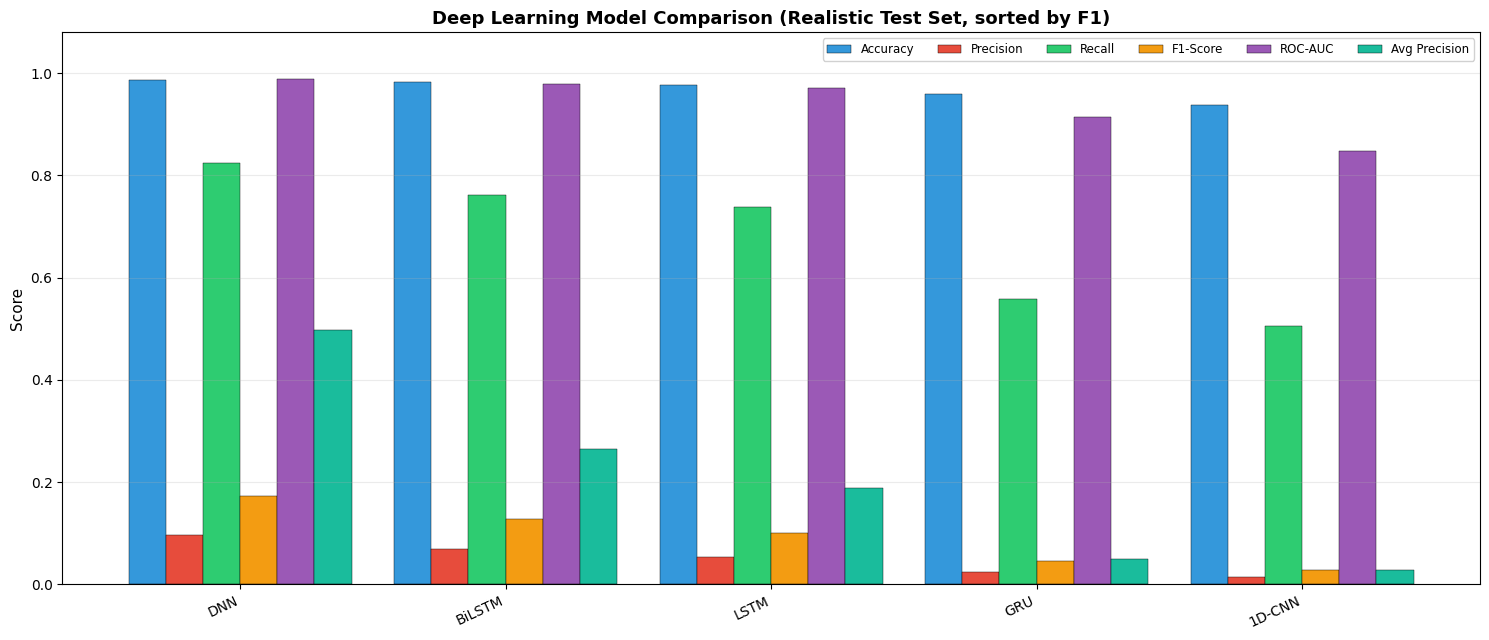

In [ ]:
# Compare
import matplotlib.pyplot as plt

# res_s_dl / res_r_dl sorted above
metrics_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'Avg Precision']
colors = ['#3498db', '#e74c3c', '#2ecc71', '#f39c12', '#9b59b6', '#1abc9c']

def plot_dl_bar(res_df, title):
    dfp = res_df.set_index('Model')[metrics_plot]
    ax = dfp.plot(kind='bar', figsize=(15, 6.5), width=0.84,
                  edgecolor='black', linewidth=0.3, color=colors)
    ax.set_title(title, fontweight='bold', fontsize=13)
    ax.set_ylabel('Score', fontsize=11)
    ax.set_ylim(0, 1.08)
    ax.set_xlabel('')
    ax.legend(loc='upper right', ncol=6, fontsize=8.5, framealpha=0.9)
    ax.grid(axis='y', alpha=0.25)
    plt.xticks(rotation=25, ha='right', fontsize=10)
    plt.tight_layout()
    plt.show()

plot_dl_bar(res_r_dl, 'Deep Learning Model Comparison (Realistic Test Set, sorted by F1)')

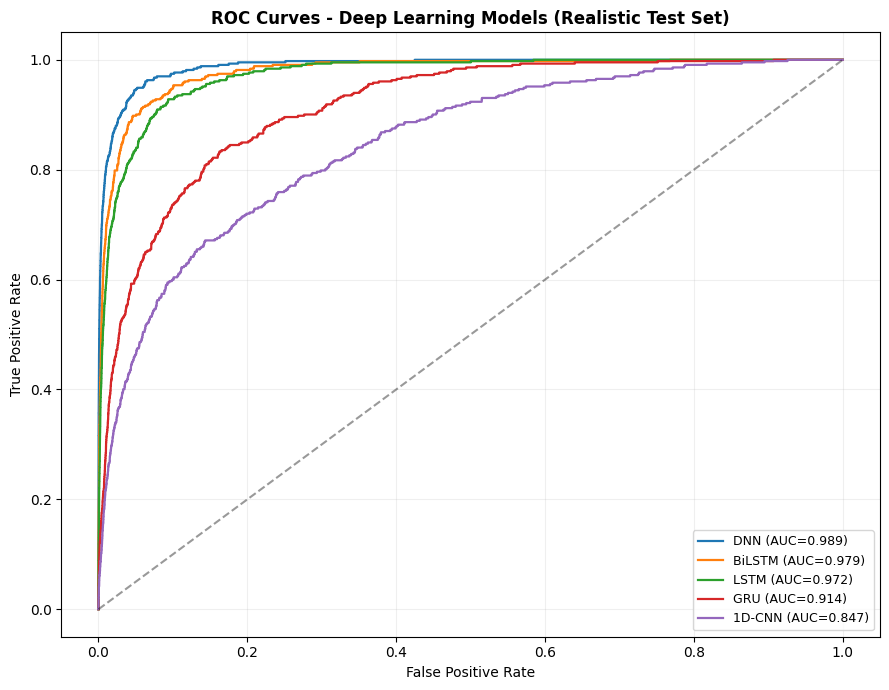

In [ ]:
# ROC
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

def plot_roc_dl(proba_dict, test_y, title):
    aucs = []
    for name, proba in proba_dict.items():
        fpr, tpr, _ = roc_curve(test_y, proba)
        aucs.append((name, fpr, tpr, auc(fpr, tpr)))
    aucs.sort(key=lambda x: x[3], reverse=True)   # sort AUC

    plt.figure(figsize=(9, 7))
    for name, fpr, tpr, a in aucs:
        plt.plot(fpr, tpr, label=f'{name} (AUC={a:.3f})', linewidth=1.6)
    plt.plot([0, 1], [0, 1], 'k--', alpha=0.4)
    plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
    plt.title(title, fontweight='bold')
    plt.legend(loc='lower right', fontsize=9); plt.grid(alpha=0.2)
    plt.tight_layout(); plt.show()

plot_roc_dl(proba_realistic, yr_a, 'ROC Curves - Deep Learning Models (Realistic Test Set)')

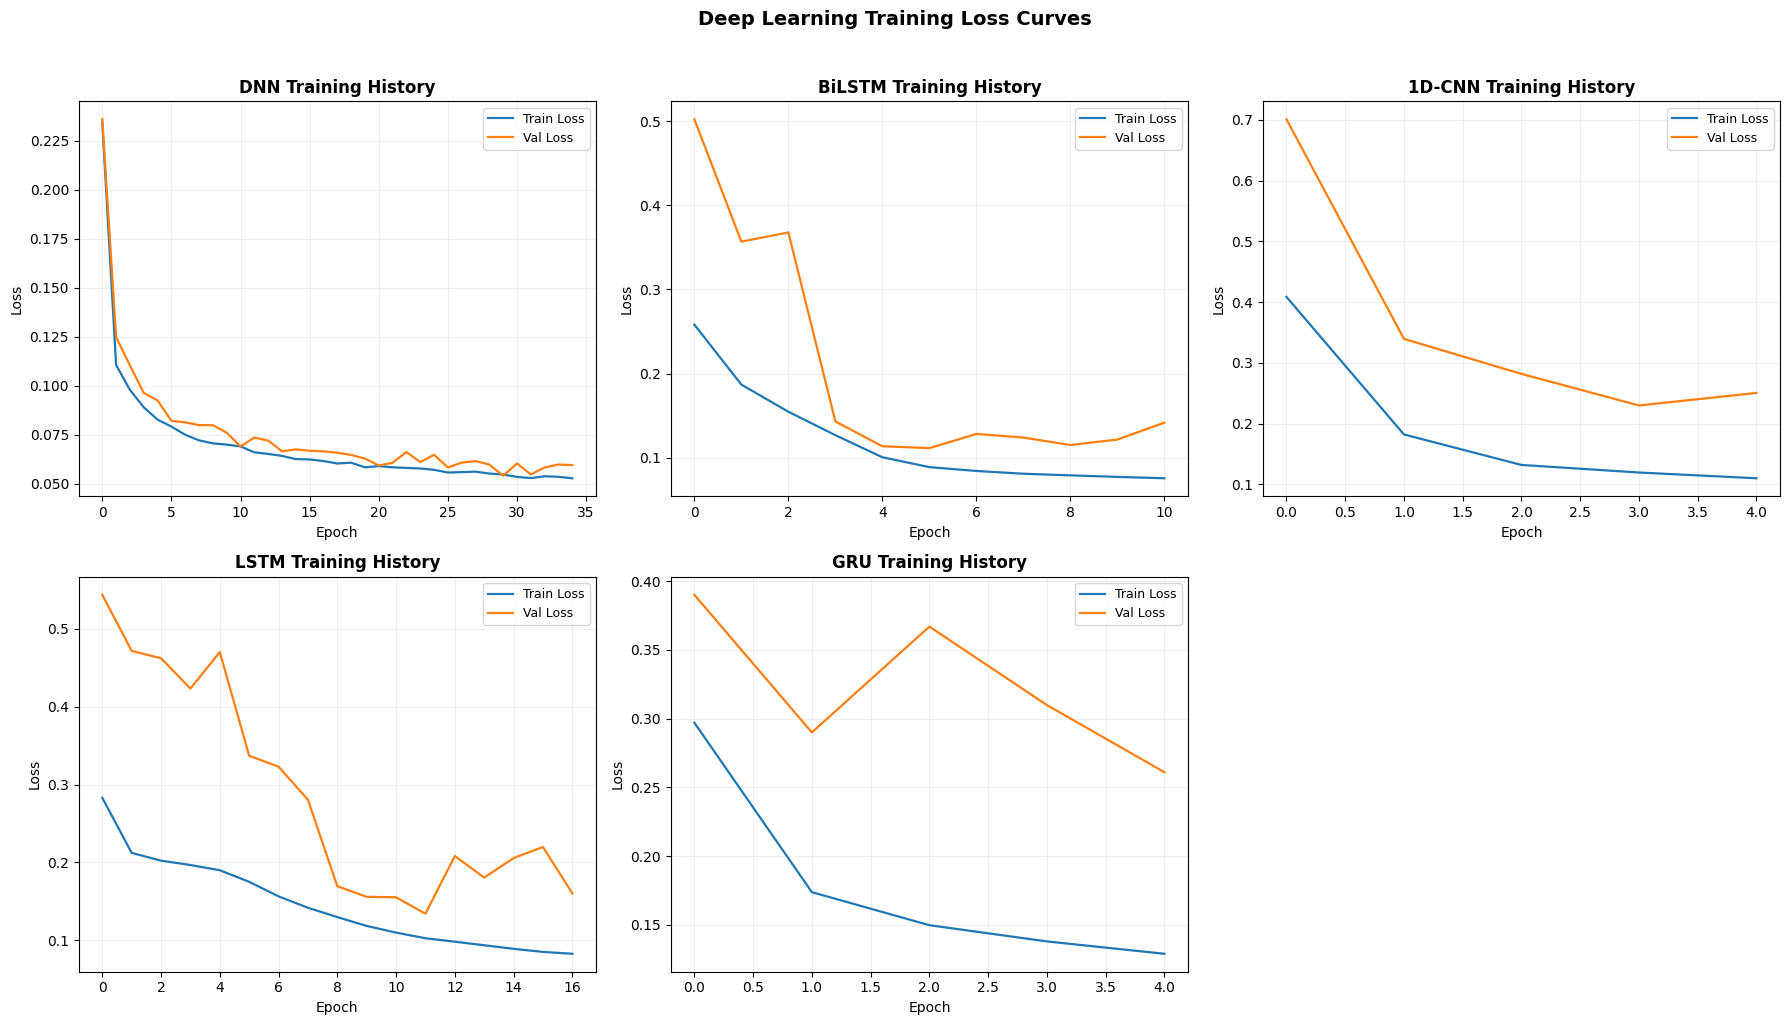

In [ ]:
import matplotlib.pyplot as plt

model_order = ['DNN', 'BiLSTM', '1D-CNN', 'LSTM', 'GRU']   # sắp theo tốt → kém

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, name in enumerate(model_order):
    hist = trained_models[name].history.history
    axes[i].plot(hist['loss'], label='Train Loss', linewidth=1.6)
    axes[i].plot(hist['val_loss'], label='Val Loss', linewidth=1.6)
    axes[i].set_title(f'{name} Training History', fontweight='bold')
    axes[i].set_xlabel('Epoch'); axes[i].set_ylabel('Loss')
    axes[i].legend(fontsize=9); axes[i].grid(alpha=0.2)

axes[-1].axis('off')

plt.suptitle('Deep Learning Training Loss Curves', fontweight='bold', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

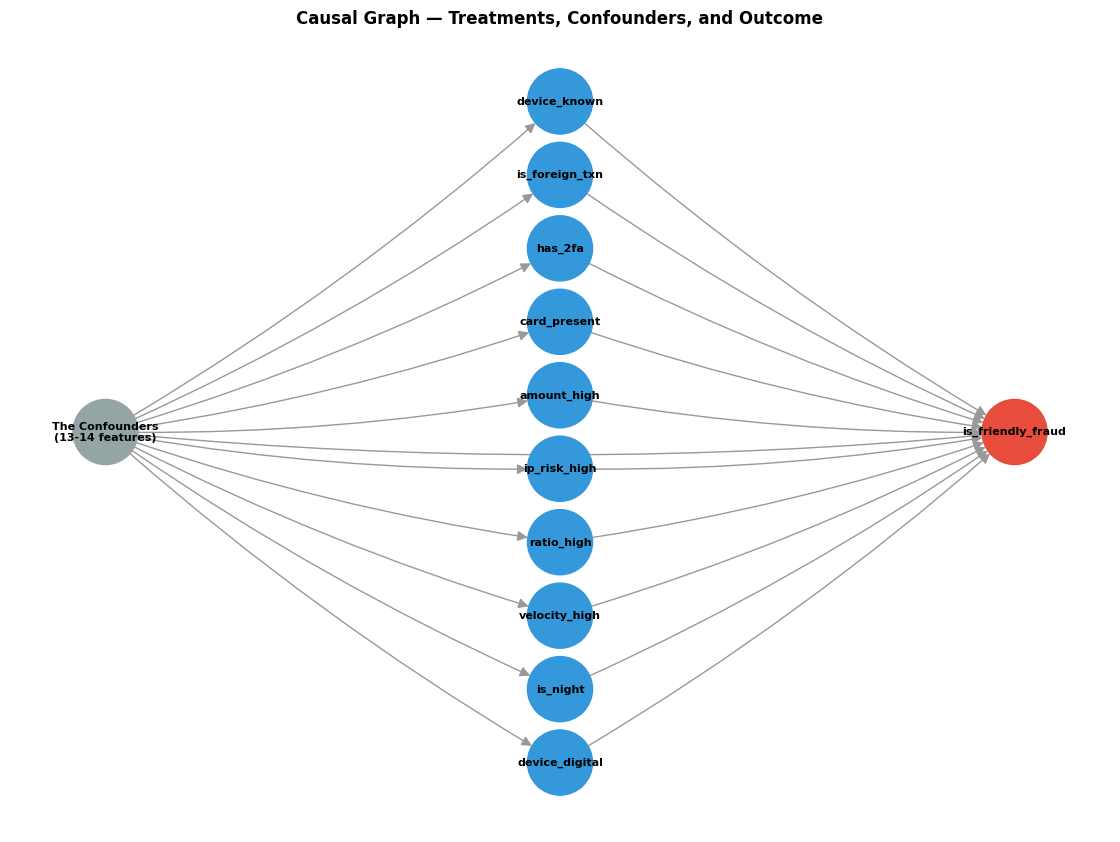

In [ ]:
# Graph
import matplotlib.pyplot as plt
import networkx as nx

#   10 treatments + outcome + backgr
treatments = ['device_known', 'is_foreign_txn', 'has_2fa', 'card_present',
              'amount_high', 'ip_risk_high', 'ratio_high', 'velocity_high',
              'is_night', 'device_digital']
outcome = 'is_friendly_fraud'
background = 'The Confounders\n(13-14 features)'

# Graph
G = nx.DiGraph()
for t in treatments:
    G.add_edge(t, outcome)
    G.add_edge(background, t)
G.add_edge(background, outcome)

#  NODE: 10 treatment, background and, outcome
pos = {t: (0, i) for i, t in enumerate(reversed(treatments))}
pos[background] = (-2.5, len(treatments) / 2 - 0.5)
pos[outcome]     = (2.5, len(treatments) / 2 - 0.5)

#  Draw
node_colors = ['#3498db' if n in treatments else '#e74c3c' if n == outcome else '#95a5a6'
              for n in G.nodes()]

plt.figure(figsize=(11, 8))
nx.draw(G, pos, with_labels=True, node_color=node_colors, node_size=2200,
        font_size=8, font_weight='bold', arrowsize=15, edge_color='#999999',
        connectionstyle='arc3,rad=0.05')
plt.title('Causal Graph — Treatments, Confounders, and Outcome', fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
# 4.5.4 Treatment Effect Estimation
import pandas as pd, numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import NearestNeighbors
import warnings; warnings.filterwarnings('ignore')

# 1. Read file + Encode
df = pd.read_excel('/content/sample_data/friendly_fraud_only.xlsx')
df['is_friendly_fraud'] = (df['fraud_pattern'] == 'friendly_fraud').astype(int)

df_ml = df.copy()
for col in ['merchant_category', 'device_type', 'merchant_country']:
    df_ml[col] = LabelEncoder().fit_transform(df_ml[col].astype(str))

feature_columns = ['amount','ip_risk_score','time_since_last_s','velocity_1h',
    'amount_vs_avg_ratio','account_age_days','credit_limit','hour_of_day',
    'day_of_week','is_weekend','card_present','device_known','is_foreign_txn',
    'has_2fa','mcc_code','merchant_category','device_type','merchant_country']

# 2. Binning + Binarize  — Create 6 new treatments
df_ml['amount_cat'] = pd.cut(df['amount'], bins=[0, 100, 500, float('inf')],
    labels=['Low', 'Medium', 'High'], include_lowest=True)
df_ml['ip_risk_cat'] = pd.cut(df['ip_risk_score'], bins=[0, 30, 60, float('inf')],
    labels=['Low', 'Medium', 'High'], include_lowest=True)
df_ml['ratio_cat'] = pd.cut(df['amount_vs_avg_ratio'], bins=[0, 2, 10, float('inf')],
    labels=['Low', 'Medium', 'High'], include_lowest=True)
df_ml['velocity_cat'] = pd.cut(df['velocity_1h'], bins=[-1, 1, 3, float('inf')],
    labels=['Low', 'Medium', 'High'])
df_ml['hour_period'] = pd.cut(df['hour_of_day'], bins=[-1, 6, 12, 18, 24],
    labels=['Night', 'Morning', 'Afternoon', 'Evening'])

df_ml['amount_high']   = (df_ml['amount_cat']   == 'High').astype(int)
df_ml['ip_risk_high']  = (df_ml['ip_risk_cat']  == 'High').astype(int)
df_ml['ratio_high']    = (df_ml['ratio_cat']    == 'High').astype(int)
df_ml['velocity_high'] = (df_ml['velocity_cat'] == 'High').astype(int)
df_ml['is_night']      = (df_ml['hour_period']  == 'Night').astype(int)

digital_devices = ['mobile_app', 'web_browser']
df_ml['device_digital'] = df['device_type'].isin(digital_devices).astype(int)


#  List 10 treaments
new_numeric_treatments = ['amount_high', 'ip_risk_high', 'ratio_high',
                          'velocity_high', 'is_night']
categorical_treatments = ['card_present', 'device_known', 'is_foreign_txn',
                          'has_2fa', 'device_digital']
treatments = new_numeric_treatments + categorical_treatments
feature_columns_ext = feature_columns + new_numeric_treatments + ['device_digital']

#  Sample: The full dataset is too big, so just use 50k records like ML
fraud_df = df_ml[df_ml['is_friendly_fraud'] == 1]
legit_df = df_ml[df_ml['is_friendly_fraud'] == 0].sample(n=50000, random_state=42)
df_causal = pd.concat([fraud_df, legit_df]).sample(frac=1, random_state=42).reset_index(drop=True)
df_causal = df_causal[feature_columns_ext + ['is_friendly_fraud']].copy()


# Calculate SMD + Propensity matching
def compute_smd(data, treatment, confounders):
    t_grp = data[data[treatment] == 1]
    c_grp = data[data[treatment] == 0]
    smd = {}
    for col in confounders:
        mean_t, mean_c = t_grp[col].mean(), c_grp[col].mean()
        var_t, var_c = t_grp[col].var(), c_grp[col].var()
        pooled_std = np.sqrt((var_t + var_c) / 2)
        smd[col] = 0 if pooled_std == 0 else abs(mean_t - mean_c) / pooled_std
    return pd.Series(smd)

def propensity_match(data, treatment, confounders, random_state=42):
    X = data[confounders].values
    y = data[treatment].values
    ps_model = LogisticRegression(max_iter=1000, random_state=random_state)
    ps_model.fit(X, y)
    data = data.copy()
    data['propensity_score'] = ps_model.predict_proba(X)[:, 1]
    treated = data[data[treatment] == 1]
    control = data[data[treatment] == 0]
    nn = NearestNeighbors(n_neighbors=1)
    nn.fit(control[['propensity_score']])
    _, idx = nn.kneighbors(treated[['propensity_score']])
    matched_control = control.iloc[idx.flatten()]
    return pd.concat([treated, matched_control])


# Compare BALANCE — WITH vs WITHOUT merchant_country (for is_foreign_txn)
t = 'is_foreign_txn'

confounders_with = [c for c in feature_columns_ext if c not in set(treatments)]
before_smd_with = compute_smd(df_causal, t, confounders_with)
matched_with = propensity_match(df_causal, t, confounders_with)
after_smd_with = compute_smd(matched_with, t, confounders_with)

confounders_without = [c for c in feature_columns_ext if c not in set(treatments) | {'merchant_country'}]
before_smd_without = compute_smd(df_causal, t, confounders_without)
matched_without = propensity_match(df_causal, t, confounders_without)
after_smd_without = compute_smd(matched_without, t, confounders_without)

comparison = pd.DataFrame({
    'With merchant_country': [
        round(before_smd_with.max(), 3),
        round(after_smd_with.max(), 3),
        f"{(before_smd_with < 0.1).sum()} / {len(confounders_with)}",
        f"{(after_smd_with < 0.1).sum()} / {len(confounders_with)}",
    ],
    'Without merchant_country': [
        round(before_smd_without.max(), 3),
        round(after_smd_without.max(), 3),
        f"{(before_smd_without < 0.1).sum()} / {len(confounders_without)}",
        f"{(after_smd_without < 0.1).sum()} / {len(confounders_without)}",
    ]
}, index=['Max SMD before matching', 'Max SMD after matching',
         'Features with SMD < 0.1 (before)', 'Features with SMD < 0.1 (after)'])

print(f"\nBALANCE CHECK: is_foreign_txn — WITH vs WITHOUT merchant_country\n")
print(comparison.to_string())


BALANCE CHECK: is_foreign_txn — WITH vs WITHOUT merchant_country

                                 With merchant_country Without merchant_country
Max SMD before matching                          3.061                    1.063
Max SMD after matching                           3.848                    0.141
Features with SMD < 0.1 (before)               11 / 14                  11 / 13
Features with SMD < 0.1 (after)                 0 / 14                  12 / 13


In [ ]:

# BALANCE SUMMARY — For all 10 treatments
raw_source = {
    'amount_high':    'amount',
    'ip_risk_high':   'ip_risk_score',
    'ratio_high':     'amount_vs_avg_ratio',
    'velocity_high':  'velocity_1h',
    'is_night':       'hour_of_day',
    'device_digital': 'device_type',
    'is_foreign_txn': 'merchant_country',
}

balance_summary = []
for t in treatments:
    exclude = set(treatments) | {raw_source.get(t, '')}
    confounders = [c for c in feature_columns_ext if c not in exclude]

    before_smd = compute_smd(df_causal, t, confounders)
    matched = propensity_match(df_causal, t, confounders)
    after_smd = compute_smd(matched, t, confounders)

    n_ok_before = (before_smd < 0.1).sum()
    n_ok_after  = (after_smd < 0.1).sum()

    balance_summary.append({
        'Treatment': t,
        'Features': len(confounders),
        'SMD<0.1 Before': f"{n_ok_before}/{len(confounders)}",
        'SMD<0.1 After':  f"{n_ok_after}/{len(confounders)}",
        'Max SMD Before': round(before_smd.max(), 3),
        'Max SMD After':  round(after_smd.max(), 3),
    })

summary_df = pd.DataFrame(balance_summary)
print(f"\n  COVARIATE BALANCE SUMMARY — All 10 treatments\n")
print(summary_df.to_string(index=False))


  COVARIATE BALANCE SUMMARY — All 10 treatments

     Treatment  Features SMD<0.1 Before SMD<0.1 After  Max SMD Before  Max SMD After
   amount_high        13           9/13         11/13           1.354          0.170
  ip_risk_high        13           9/13         12/13           0.739          0.175
    ratio_high        13           8/13         11/13           1.776          0.151
 velocity_high        13           9/13         12/13           0.809          0.182
      is_night        13          13/13         13/13           0.045          0.029
  card_present        14          13/14         11/14           0.115          0.160
  device_known        14          12/14         14/14           0.291          0.043
is_foreign_txn        13          11/13         12/13           1.063          0.141
       has_2fa        14          14/14         14/14           0.028          0.018
device_digital        13          13/13         13/13           0.028          0.021


In [ ]:
!pip install dowhy --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 403.1/403.1 kB 18.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 245.9/245.9 kB 13.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 99.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 58.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.1/12.1 MB 83.3 MB/s eta 0:00:00


In [ ]:
# Calculate the ATE

from dowhy import CausalModel
import logging; logging.getLogger("dowhy").setLevel(logging.ERROR)

ate_results = []
for t in treatments:
    exclude = set(treatments) | {raw_source.get(t, '')}
    confounders = [c for c in feature_columns_ext if c not in exclude]

    model = CausalModel(data=df_causal, treatment=t, outcome='is_friendly_fraud',
                        common_causes=confounders)
    identified = model.identify_effect(proceed_when_unidentifiable=True)
    estimate = model.estimate_effect(identified, method_name='backdoor.propensity_score_matching')

    ate_results.append({'Treatment': t, 'ATE': round(estimate.value, 3)})

ate_df = pd.DataFrame(ate_results)

# ── + with Max SMD After which calculated before in summary_df ─────────────────────
final_df = ate_df.merge(summary_df[['Treatment', 'Max SMD After']], on='Treatment')
final_df = final_df.rename(columns={'Max SMD After': 'Max SMD After Matching'})
final_df = final_df.sort_values('ATE', key=abs, ascending=False).reset_index(drop=True)

print(f"\n ATE for all 10 treatments\n")
print(final_df.to_string(index=False))


 ATE for all 10 treatments

     Treatment    ATE  Max SMD After Matching
 velocity_high  0.437                   0.182
  ip_risk_high  0.278                   0.175
  device_known -0.138                   0.043
    ratio_high -0.075                   0.151
   amount_high  0.048                   0.170
is_foreign_txn  0.043                   0.141
      is_night  0.020                   0.029
  card_present -0.013                   0.160
device_digital  0.013                   0.021
       has_2fa -0.010                   0.018


In [ ]:
# Feature importance for XGBoost
import pandas as pd, numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
import warnings; warnings.filterwarnings('ignore')

# Read file + Encode
df = pd.read_excel('/content/sample_data/friendly_fraud_only.xlsx')
df['is_friendly_fraud'] = (df['fraud_pattern'] == 'friendly_fraud').astype(int)

df_ml = df.copy()
for col in ['merchant_category', 'device_type', 'merchant_country']:
    df_ml[col] = LabelEncoder().fit_transform(df_ml[col].astype(str))

feature_columns = ['amount','ip_risk_score','time_since_last_s','velocity_1h',
    'amount_vs_avg_ratio','account_age_days','credit_limit','hour_of_day',
    'day_of_week','is_weekend','card_present','device_known','is_foreign_txn',
    'has_2fa','mcc_code','merchant_category','device_type','merchant_country']

# Undersample 50k → Split 75:25 → SMOTE → Scale
fraud = df_ml[df_ml['is_friendly_fraud'] == 1]
legit = df_ml[df_ml['is_friendly_fraud'] == 0].sample(n=50000, random_state=42)
data = pd.concat([fraud, legit]).reset_index(drop=True)

X, y = data[feature_columns], data['is_friendly_fraud']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
X_tr, y_tr = SMOTE(sampling_strategy=0.5, random_state=42).fit_resample(X_tr, y_tr)

sc = StandardScaler()
X_tr_s = sc.fit_transform(X_tr)

# Train XGBOOST + Calcuate IMPORTANCE (gain metric)
xgb_model = XGBClassifier(random_state=42, eval_metric='logloss', use_label_encoder=False,
                          n_jobs=-1, importance_type='gain')
xgb_model.fit(X_tr_s, y_tr)

xgb_importance = pd.Series(xgb_model.feature_importances_, index=feature_columns)
xgb_importance = (xgb_importance / xgb_importance.sum() * 100).round(1).sort_values(ascending=False)

print(" XGBoost Feature Importance")
print(xgb_importance.astype(str) + '%')


── XGBoost Feature Importance (gain, normalized to %) ──
ip_risk_score          34.0%
device_known           22.3%
velocity_1h            14.8%
is_foreign_txn          8.5%
card_present            3.8%
device_type             3.5%
is_weekend              3.0%
merchant_country        2.8%
has_2fa                 1.9%
mcc_code                1.2%
merchant_category       0.7%
amount                  0.6%
amount_vs_avg_ratio     0.6%
account_age_days        0.5%
credit_limit            0.5%
day_of_week             0.5%
hour_of_day             0.5%
time_since_last_s       0.4%
dtype: object


In [ ]:
# DNN Feature Importants
import pandas as pd, numpy as np
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from imblearn.over_sampling import SMOTE
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
import warnings; warnings.filterwarnings('ignore')

# Read file + Encode
df = pd.read_excel('/content/sample_data/friendly_fraud_only.xlsx')
df['is_friendly_fraud'] = (df['fraud_pattern'] == 'friendly_fraud').astype(int)

df_ml = df.copy()
for col in ['merchant_category', 'device_type', 'merchant_country']:
    df_ml[col] = LabelEncoder().fit_transform(df_ml[col].astype(str))

feature_columns = ['amount','ip_risk_score','time_since_last_s','velocity_1h',
    'amount_vs_avg_ratio','account_age_days','credit_limit','hour_of_day',
    'day_of_week','is_weekend','card_present','device_known','is_foreign_txn',
    'has_2fa','mcc_code','merchant_category','device_type','merchant_country']

# Sample + Split + Smote + Scale
fraud = df_ml[df_ml['is_friendly_fraud'] == 1]
legit = df_ml[df_ml['is_friendly_fraud'] == 0].sample(n=50000, random_state=42)
data = pd.concat([fraud, legit]).reset_index(drop=True)
X, y = data[feature_columns], data['is_friendly_fraud']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
X_tr, y_tr = SMOTE(sampling_strategy=0.5, random_state=42).fit_resample(X_tr, y_tr)

sc = StandardScaler()
X_tr_s = sc.fit_transform(X_tr)
X_te_s = sc.transform(X_te)
n_feat = X_tr_s.shape[1]


# Train DNN + PERMUTATION IMPORTANCE
def build_dnn():
    return models.Sequential([
        layers.Input((n_feat,)),
        layers.Dense(128, activation='relu'), layers.BatchNormalization(), layers.Dropout(0.4),
        layers.Dense(64, activation='relu'),  layers.BatchNormalization(), layers.Dropout(0.3),
        layers.Dense(32, activation='relu'),  layers.BatchNormalization(), layers.Dropout(0.2),
        layers.Dense(1, activation='sigmoid')
    ])

def permutation_importance_dnn(model, X, y, feature_names, n_repeats=3, seed=42):
    baseline_auc = roc_auc_score(y, model.predict(X, verbose=0).ravel())
    rng = np.random.RandomState(seed)
    importances = {}
    for i, fname in enumerate(feature_names):
        drops = []
        for _ in range(n_repeats):
            X_perm = X.copy()
            rng.shuffle(X_perm[:, i])
            perm_auc = roc_auc_score(y, model.predict(X_perm, verbose=0).ravel())
            drops.append(baseline_auc - perm_auc)
        importances[fname] = np.mean(drops)
    result = pd.Series(importances).clip(lower=0)
    return (result / result.sum() * 100)   # % not sorted yet

# .Run 3 times, Every train is done with different seed
all_runs = []
es = callbacks.EarlyStopping(patience=5, restore_best_weights=True, monitor='val_loss')

for run in range(3):
    seed = 42 + run
    tf.keras.utils.set_random_seed(seed)

    dnn = build_dnn()
    dnn.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='binary_crossentropy')
    dnn.fit(X_tr_s, y_tr.values, validation_split=0.15, epochs=50, batch_size=256,
            callbacks=[es], verbose=0)

    imp = permutation_importance_dnn(dnn, X_te_s, y_te.values, feature_columns, seed=seed)
    all_runs.append(imp)

# Then take avg for 3 times
avg_importance = pd.concat(all_runs, axis=1).mean(axis=1).sort_values(ascending=False)

print(f"\n DNN Important — Average of 3 runs\n")
print((avg_importance.round(1)).astype(str) + '%')

print(f"\nTop 5 features: {avg_importance.head(5).round(1).to_dict()}")


 DNN Important — Average of 3 runs

ip_risk_score          62.2%
velocity_1h            23.1%
is_foreign_txn          5.2%
device_known            4.1%
merchant_country        3.6%
card_present            0.5%
amount_vs_avg_ratio     0.3%
hour_of_day             0.2%
amount                  0.2%
merchant_category       0.2%
is_weekend              0.2%
account_age_days        0.1%
device_type             0.1%
credit_limit            0.0%
has_2fa                 0.0%
day_of_week             0.0%
time_since_last_s       0.0%
mcc_code                0.0%
dtype: object

Top 5 features: {'ip_risk_score': 62.2, 'velocity_1h': 23.1, 'is_foreign_txn': 5.2, 'device_known': 4.1, 'merchant_country': 3.6}


In [ ]:
#4.1.6
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# --- Plot 1: Friendly Fraud Rate by Hour ---
fraud_by_hour = df.groupby('hour_of_day')['is_friendly_fraud'].mean() * 100

axes[0].bar(fraud_by_hour.index, fraud_by_hour.values, color='salmon', edgecolor='black', linewidth=0.5)
axes[0].set_title('Friendly Fraud Rate by Hour', fontweight='bold', fontsize=13)
axes[0].set_xlabel('Hour of Day', fontsize=11)
axes[0].set_ylabel('Fraud Rate (%)', fontsize=11)
axes[0].tick_params(labelsize=10)

# --- Plot 2: Transaction Velocity (1h) Distribution ---
legit = df[df['is_friendly_fraud'] == 0]['velocity_1h']
fraud = df[df['is_friendly_fraud'] == 1]['velocity_1h']

max_val = int(df['velocity_1h'].max())

axes[1].bar(np.arange(0, max_val + 1) - 0.2,
            [len(legit[legit == v]) / len(legit) for v in range(max_val + 1)],
            width=0.4, color='green', label='Legitimate', edgecolor='black', linewidth=0.5)
axes[1].bar(np.arange(0, max_val + 1) + 0.2,
            [len(fraud[fraud == v]) / len(fraud) for v in range(max_val + 1)],
            width=0.4, color='red', label='Friendly Fraud', edgecolor='black', linewidth=0.5)

axes[1].set_title('Transaction Velocity (1h) Distribution', fontweight='bold', fontsize=13)
axes[1].set_xlabel('Transactions per Hour', fontsize=11)
axes[1].set_ylabel('Density', fontsize=11)
axes[1].legend(fontsize=10)
axes[1].tick_params(labelsize=10)
axes[1].set_xlim(-0.5, 12.5)

# --- Plot 3: Time Since Last Transaction (s) Distribution ---
legit_tsl = df[df['is_friendly_fraud'] == 0]['time_since_last_s']
fraud_tsl = df[df['is_friendly_fraud'] == 1]['time_since_last_s']

upper = df['time_since_last_s'].quantile(0.99)
bins = np.linspace(0, upper, 40)

axes[2].hist(legit_tsl, bins=bins, density=True, alpha=0.6, color='green',
             edgecolor='black', linewidth=0.5, label='Legitimate')
axes[2].hist(fraud_tsl, bins=bins, density=True, alpha=0.6, color='red',
             edgecolor='black', linewidth=0.5, label='Friendly Fraud')